# Chapter 14: Computer Vision

# 14.1 Image Augmentation

* Method to expand dataset and also make model more robust by enacting series of random changes to training images
* Random tweaks help inject noise and could force model to focus less on certain characteristics, and focus more on abstract qualities, hereby aiding generalization  (e.g. crop images, block out certain portions, color shift, rotations, translations, etc.)

In [1]:
%matplotlib inline
import torch
import torchvision
from torch import nn
from d2l import torch as d2l

### 14.1.1 Common Image Augmentation Methods

* Will be using $400 \times 500$ image for example

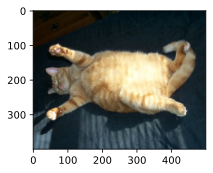

In [2]:
d2l.set_figsize()
img = d2l.Image.open('../img/cat1.jpg')
d2l.plt.imshow(img)

In [3]:
# Rune image augmentation method specified by "aug" on input image "img" multiple times and 
# displays augmented images
def apply(img, aug, num_rows=2, num_cols=4, scale=1.5):
    Y = [aug(img) for _ in range(num_rows * num_cols)]
    d2l.show_images(Y, num_rows, num_cols, scale=scale)

Flipping 
* Flipping image left & right does not change category of object
* Can be done by using *transforms* module to create a *RandomHorizontalFlip* instance which can flip the image left and right w/ a 50% chance
* Apparently, flipping up & down is not as common as left and right, but at least for image in question, doing so will not change the task at hand
    * This can be done with a *RandomVerticalFlip* instance

Cropping
* In original image, see that the cat is in the middle of the image, but that is not a garuntee in prediction mode
* Both convolutional filters and MaxPooling help with translational invaraicnce, but we could further enhance this by cropping images randomly to make image appear in different positions at different scales which would help the model learn more abstract representations and not fixate on noise  

Changing Colors
* Can change the 4 aspects of image color
    1. Brightness
    1. Contrast
    1. Saturation
    1. Hue

Combining Multiple Image Augmentation Methods
* Possible to combine all different image augmentation methods mentioned above
* Use a *Compose* instance of *torchvision.transforms.Compose*

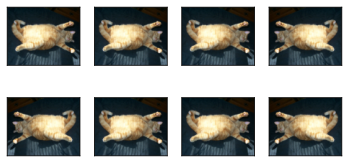

In [4]:
# Horizontal flip at 50%
# https://docs.pytorch.org/vision/main/generated/torchvision.transforms.RandomHorizontalFlip.html
apply(img, torchvision.transforms.RandomHorizontalFlip())

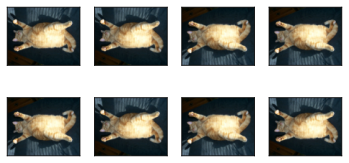

In [5]:
# Vertical flip at 50%
# https://docs.pytorch.org/vision/main/generated/torchvision.transforms.RandomVerticalFlip.html
apply(img, torchvision.transforms.RandomVerticalFlip())

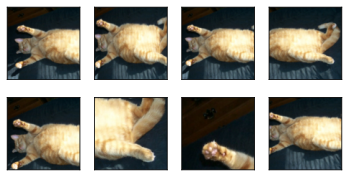

In [6]:
# Randomly Crop & Resize

# Randomly crop input with area of 10-100% of original size 
# Ratio of width-to-height of cropped area is between 0.5 and 2
# Resized to 200x200
# https://docs.pytorch.org/vision/main/generated/torchvision.transforms.RandomResizedCrop.html

shape_aug = torchvision.transforms.RandomResizedCrop(
    (200, 200), scale=(0.1, 1), ratio=(0.5, 2))
apply(img, shape_aug)

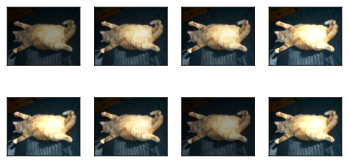

In [7]:
# Randomly change brightness of image btween 50%-150% (1-0.5)-to-(1+0.5) of original image
# https://docs.pytorch.org/vision/main/generated/torchvision.transforms.ColorJitter.html 
apply(img, torchvision.transforms.ColorJitter(
    brightness=0.5, contrast=0, saturation=0, hue=0))

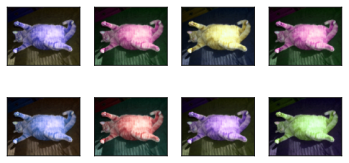

In [8]:
# Randomly change the hue of the image
# Hue: property of color that allows it to be classified as red, green, blue, etc.
# https://docs.pytorch.org/vision/main/generated/torchvision.transforms.ColorJitter.html 
apply(img, torchvision.transforms.ColorJitter(
    brightness=0, contrast=0, saturation=0, hue=0.5))

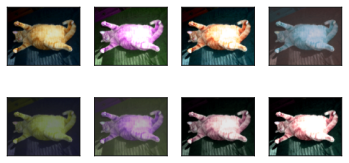

In [9]:
# Can change brightness, contrast, saturation, hue all at the same time
color_aug = torchvision.transforms.ColorJitter(
    brightness=0.5, contrast=0.5, saturation=0.5, hue=0.5)
apply(img, color_aug)

### 14.1.2 Training with Image Augmentation

* In practice, combine multiple image augmentation methods and apply them to each image via a *Compose* instance
* Use CIFAR-10 dataset instead of Fashion-MNIST due to position and size of objects being normalized in the latter, while CIFAR-10 has a wider variety of color and sizes
* Use image/data augmentation during training, but not during prediction
* Will only use simplest left-right flipping augment here
* *ToTensor* instance to convert a minibtach of images into format required by framework (32-bit floating point btween 0 and 1, with shape given by (batch example count, channel count, height, width))
    * https://docs.pytorch.org/vision/main/generated/torchvision.transforms.ToTensor.html


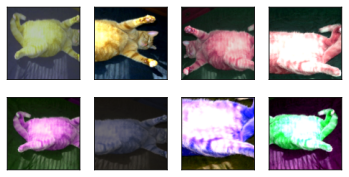

In [10]:
# Example of multiple image augmentations applied simultaenously using torchvision.transforms.Compose
# https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.Compose.html
color_aug = torchvision.transforms.ColorJitter(brightness=0.5, contrast=0.5, saturation=0.5, hue=0.5)
shape_aug = torchvision.transforms.RandomResizedCrop((200, 200), scale=(0.1, 1), ratio=(0.5, 2))

augs = torchvision.transforms.Compose([
    torchvision.transforms.RandomHorizontalFlip(), color_aug, shape_aug])
apply(img, augs)

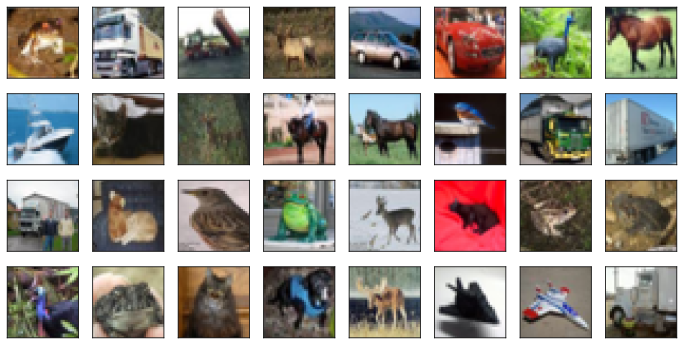

In [ ]:
# Download the CIFAR-10 dataset and display some of the first 32 images
all_images = torchvision.datasets.CIFAR10(train=True, root="../data",
                                          download=True)
d2l.show_images([all_images[i][0] for i in range(32)], num_rows=4, num_cols=8);
# NOTE: In Jupyter notebooks, the semicolon at the end of the line suppresses the line's return value

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >], dtype=object)

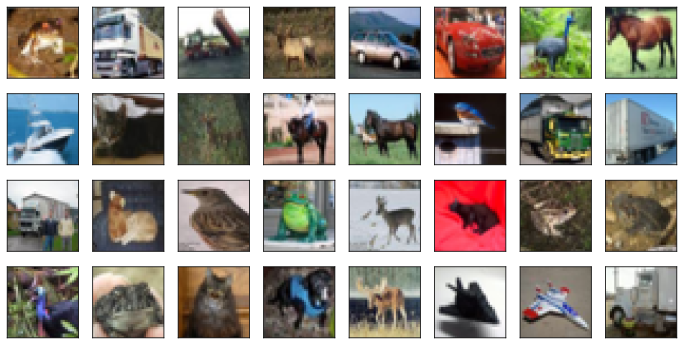

In [15]:
# Download the CIFAR-10 dataset and display some of the first 32 images
all_images = torchvision.datasets.CIFAR10(train=True, root="../data",
                                          download=True)
d2l.show_images([all_images[i][0] for i in range(32)], num_rows=4, num_cols=8)

In [17]:
train_augs = torchvision.transforms.Compose([
     torchvision.transforms.RandomHorizontalFlip(),
     torchvision.transforms.ToTensor()])

test_augs = torchvision.transforms.Compose([
     torchvision.transforms.ToTensor()])


def load_cifar10(is_train, augs, batch_size):
    dataset = torchvision.datasets.CIFAR10(root="../data", train=is_train,
                                           transform=augs, download=True)
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size,
                    shuffle=is_train, num_workers=d2l.get_dataloader_workers())
    return dataloader

Multi-GPU Training

In [27]:

def train_batch_ch13(net, X, y, loss, trainer, devices):
    """Train for a minibatch with multiple GPUs (defined in Chapter 13)."""
    if isinstance(X, list):
        # Required for BERT fine-tuning (to be covered later)
        X = [x.to(devices[0]) for x in X]
    else:
        X = X.to(devices[0])
    y = y.to(devices[0])
    net.train()
    trainer.zero_grad()
    pred = net(X)
    l = loss(pred, y)
    l.sum().backward()
    trainer.step()
    train_loss_sum = l.sum()
    train_acc_sum = d2l.accuracy(pred, y)
    return train_loss_sum, train_acc_sum


def train_ch13(net, train_iter, test_iter, loss, trainer, num_epochs,
               devices=d2l.try_all_gpus()):
    """Train a model with multiple GPUs (defined in Chapter 13)."""
    timer, num_batches = d2l.Timer(), len(train_iter)
    animator = d2l.Animator(xlabel='epoch', xlim=[1, num_epochs], ylim=[0, 1],
                            legend=['train loss', 'train acc', 'test acc'])
    net = nn.DataParallel(net, device_ids=devices).to(devices[0])
    for epoch in range(num_epochs):
        # Sum of training loss, sum of training accuracy, no. of examples,
        # no. of predictions
        metric = d2l.Accumulator(4)
        for i, (features, labels) in enumerate(train_iter):
            timer.start()
            l, acc = train_batch_ch13(
                net, features, labels, loss, trainer, devices)
            metric.add(l, acc, labels.shape[0], labels.numel())
            timer.stop()
            if (i + 1) % (num_batches // 5) == 0 or i == num_batches - 1:
                animator.add(epoch + (i + 1) / num_batches,
                             (metric[0] / metric[2], metric[1] / metric[3],
                              None))
        test_acc = d2l.evaluate_accuracy_gpu(net, test_iter)
        animator.add(epoch + 1, (None, None, test_acc))
    print(f'loss {metric[0] / metric[2]:.3f}, train acc '
          f'{metric[1] / metric[3]:.3f}, test acc {test_acc:.3f}')
    print(f'{metric[2] * num_epochs / timer.sum():.1f} examples/sec on '
          f'{str(devices)}')
    

batch_size = 256
devices = d2l.try_all_gpus()
net = d2l.resnet18(10, 3).apply(d2l.init_cnn)


def train_with_data_aug(train_augs, test_augs, net, num_epochs=10, lr=0.001):
    train_iter = load_cifar10(True, train_augs, batch_size)
    test_iter = load_cifar10(False, test_augs, batch_size)
    loss = nn.CrossEntropyLoss(reduction="none")
    trainer = torch.optim.Adam(net.parameters(), lr=lr)
    net(next(iter(train_iter))[0])
    train_ch13(net, train_iter, test_iter, loss, trainer, num_epochs=num_epochs, devices=devices)

loss 0.198, train acc 0.931, test acc 0.832
5065.8 examples/sec on [device(type='cuda', index=0)]


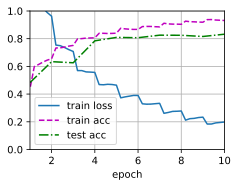

In [19]:
train_with_data_aug(train_augs, test_augs, net)

### 14.1.3 Summary

* Image augmentation generates random version of preexisting training to help robustness and generalization of models
* Only apply data/image augmentation during traiing (not during prediction)
* PyTorch, along with other frameworks provides many different image augmentation methods which can be applied one at a time, or simultanously

### 14.1.4 Exercises
1. Train the model without using image augmentation: `train_with_data_aug(test_augs, test_augs)`. Compare training and testing accuracy when using and not using image augmentation. Can this comparative experiment support the argument that image augmentation can mitigate overfitting? Why?
1. Combine multiple different image augmentation methods in model training on the CIFAR-10 dataset. Does it improve test accuracy? 
1. Refer to the online documentation of the deep learning framework. What other image augmentation methods does it also provide?


Exercise #1
* Model without image augmentation
    * Train Loss: 0.095
    * Train Acc: 0.967
    * Val Acc: 0.820
    * Relatively large discrepancy between Train Acc and Val Acc inidcates overfitting
* Model with image augmentation (RandomHorizontalFlip only from textbook demo)
    * Train Loss: 0.435
    * Train Acc: 0.848
    * Val Acc: 0.769
* With image augmentation, training loss is higher than without for same number of of epochs. Both training and validation accuracy are lower, but the discrepancy between them is smaller (8% points v.s. 14.7%, indicating it serves as a better regularizatino method. Note, using more transforms on top of random vertical and horizontal flips causes test and train acc to start lower and rise slower. Train and Test Acc are still rising at 10 epochs, so could still afford to increase number of epochs) 

loss 0.095, train acc 0.967, test acc 0.820
5246.3 examples/sec on [device(type='cuda', index=0)]


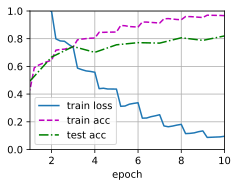

In [23]:
# Training WITHOUT any iamge augmentation

# test_augs = torchvision.transforms.Compose([torchvision.transforms.ToTensor()])
ToTensorTransform = torchvision.transforms.ToTensor()
batch_size = 256
devices = d2l.try_all_gpus()
net = d2l.resnet18(10, 3).apply(d2l.init_cnn)

train_with_data_aug(train_augs = ToTensorTransform, test_augs=ToTensorTransform, net=net)

In [21]:
all_images[0]

(<PIL.Image.Image image mode=RGB size=32x32>, 6)

loss 0.435, train acc 0.848, test acc 0.769
5274.1 examples/sec on [device(type='cuda', index=0)]


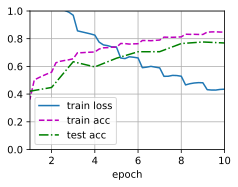

In [29]:
# Training WITH multiple image augmentations

train_augs = torchvision.transforms.Compose([
    torchvision.transforms.RandomHorizontalFlip(),
    torchvision.transforms.RandomVerticalFlip(),
    torchvision.transforms.ToTensor()
    ])
test_augs = torchvision.transforms.ToTensor()
batch_size = 256
devices = d2l.try_all_gpus()
net = d2l.resnet18(10, 3).apply(d2l.init_cnn)

train_with_data_aug(train_augs, test_augs, num_epochs=10, net=net)

Exercise #2
* Combined multiple image augmentation methods on CIFAR-10 dataset
* Just done as the "Model with image augmentation" section from Exercise #1

Exercise #3
* Other image augmentatino methods: https://docs.pytorch.org/vision/0.8/transforms.html
    * CenterCrop
    * FiveCrop
        * Crops image into 4 corners and central crop
    * GrayScale
    * Pad
    * RandomAffine
    * RandomRotation

# 14.2 Fine-Tuning

* Instead of creating dataset from scratch for every particular task, take a preexisting model and apply transfer learning to transfer knowledge learned from source dataset to target dataset
    * e.g. ImageNet was not designed for types of chair recognition, but built in representations could help with task at hand

In [31]:
%matplotlib inline
import os
import torch
import torchvision
from torch import nn
from d2l import torch as d2l

### 14.2.1 Steps

1. Pre-Train a neural network (source model) on a source dataset (say, ImageNet)
1. Copy over everything from the source model to our now target model, except the output layer. 
    1. Will be implicitly assuming that swapping out output layer is determining factor between source and target dataset. 
    1. Note the new output layer of the target model will be initialized randomly and trained from scratch.
    1. However, the rest of the pre-trained model will be copied over, but not frozen and thus fine-tuned
1. Train new model on target dataset

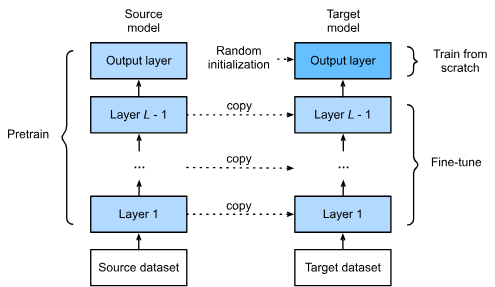

### 14.2.2 Hot Dog Recognition

* Hotdog dataset was taken from online images consistingof 1400 positive class images (i.e. hot dogs) and many images of negative class images (not hot dogs)
* 1000 images for both positive and negative classes are used for training, and the rest are for testing

In [32]:
# Downloaded data from d2l
d2l.DATA_HUB['hotdog'] = (d2l.DATA_URL + 'hotdog.zip',
                         'fba480ffa8aa7e0febbb511d181409f899b9baa5')

data_dir = d2l.download_extract('hotdog')

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object)

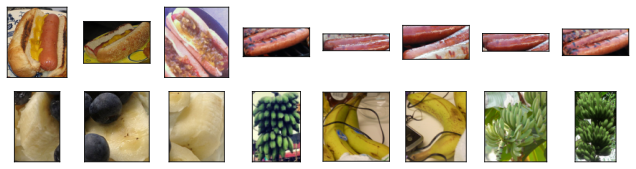

In [33]:
# https://docs.pytorch.org/vision/main/generated/torchvision.datasets.DatasetFolder.html
# https://docs.pytorch.org/vision/main/generated/torchvision.datasets.ImageFolder.html
train_imgs = torchvision.datasets.ImageFolder(os.path.join(data_dir, 'train'))
test_imgs  = torchvision.datasets.ImageFolder(os.path.join(data_dir, 'test'))

hotdogs     = [train_imgs[i][0] for i in range(8)]
not_hotdogs = [train_imgs[-i - 1][0] for i in range(8)]
d2l.show_images(hotdogs + not_hotdogs, 2, 8, scale=1.4)

* Notice how in all the  pictures above, they vary in size and aspect ratio

In [ ]:
# Specify the means and standard deviations of the three RGB channels to
# standardize each channel

# The values below are calculated from ImageNet dataset: https://en.wikipedia.org/wiki/ImageNet
# First set of 3 are means, second set are standard deviations
normalize = torchvision.transforms.Normalize(
    [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
    )

train_augs = torchvision.transforms.Compose([
    torchvision.transforms.RandomResizedCrop(224),  # Resize fo 224 for training
    torchvision.transforms.RandomHorizontalFlip(),
    torchvision.transforms.ToTensor(),
    normalize]
    )

test_augs = torchvision.transforms.Compose([
    torchvision.transforms.Resize([256, 256]),      # Resize to 256 for testing
    torchvision.transforms.CenterCrop(224),
    torchvision.transforms.ToTensor(),
    normalize])

https://docs.pytorch.org/vision/main/models.html

* pretrained source model has many feature layres and an output layer "fc". This is to make easier the fine-tuning of model parameters of all layers but the output. 
* The "fc" of a source model is can be accessed by ".fc"
* The non-last-FC layer is pretrained on ImageNet, so can be considered reliable. Therefore, if only needs to be fine-tuned while the new FC layer needs to be learned from scratch, so a learning rate of $\eta$ will be used for the copied over source model, while a learning rate of $10 \eta$ will be used for the new FC layer

In [35]:
pretrained_net = torchvision.models.resnet18(pretrained=True)

pretrained_net.fc

c:\Users\jimmy\anaconda3\envs\d2l\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\jimmy\anaconda3\envs\d2l\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Linear(in_features=512, out_features=1000, bias=True)

In [49]:
# Import pre-trained model
finetune_net = torchvision.models.resnet18(pretrained=True) # Note, this is deprecated now

# Replace last FC layer with new one with 2 output classes (hotdog & not hotdog), and number of input
# features is same as original FC layer 
# finetune_net.fc = nn.Linear(finetune_net.fc.in_features, 2)
# Can do this and trian model, but note it has no input dimension yet, so the .shape line at the end of this cell won't work
finetune_net.fc = nn.LazyLinear(2) 

# Q: Can I use LazyLinear instead of Linear?
# A: No. Need to have some initialized paramters for xavier_uniform_. If dimensinos are inferred, 
#    Then there are no paramters or how many to initialize 
# finetune_net.fc = nn.LazyLinear(2)
# nn.init.xavier_uniform_(finetune_net.fc.weight), nn.init.xavier_uniform_(finetune_net.fc.weight).shape

c:\Users\jimmy\anaconda3\envs\d2l\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\jimmy\anaconda3\envs\d2l\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [ ]:
# If `param_group=True`, the model parameters in the output layer will be
# updated using a learning rate ten times greater

def train_fine_tuning(net, learning_rate, batch_size=128, num_epochs=5, param_group=True):

    train_iter = torch.utils.data.DataLoader(torchvision.datasets.ImageFolder(
        os.path.join(data_dir, 'train'), transform=train_augs),
        batch_size=batch_size, shuffle=True)
    
    test_iter = torch.utils.data.DataLoader(torchvision.datasets.ImageFolder(
        os.path.join(data_dir, 'test'), transform=test_augs),
        batch_size=batch_size)
    
    devices = d2l.try_all_gpus()
    loss = nn.CrossEntropyLoss(reduction="none")

    if param_group: # Set lr for output layer to be 10 times greater than lr for rest of the model
        params_1x = [param for name, param in net.named_parameters()
             if name not in ["fc.weight", "fc.bias"]] # This will return all non-output/FC layer params
        trainer = torch.optim.SGD([{'params': params_1x},
                                   {'params': net.fc.parameters(),
                                    'lr': learning_rate * 10}],
                                    lr=learning_rate, weight_decay=0.001)
    else: # Same learning rate for all parameters
        trainer = torch.optim.SGD(net.parameters(), lr=learning_rate, weight_decay=0.001)

    d2l.train_ch13(net, train_iter, test_iter, loss, trainer, num_epochs, devices)

loss 0.163, train acc 0.935, test acc 0.940
1385.3 examples/sec on [device(type='cuda', index=0)]


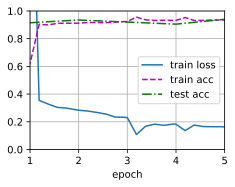

In [50]:
train_fine_tuning(finetune_net, learning_rate=5e-5)

loss 0.369, train acc 0.831, test acc 0.849
1371.6 examples/sec on [device(type='cuda', index=0)]


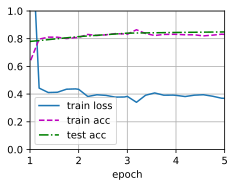

In [ ]:
# Note how a pure from-scratch model performs worse for same number of epochs since it dosen't have
# the benefit of transfer learning from pre-trained weights
scratch_net = torchvision.models.resnet18() # No pre-trained weights
scratch_net.fc = nn.Linear(scratch_net.fc.in_features, 2)
train_fine_tuning(scratch_net, learning_rate=5e-4, param_group=False)

### 14.2.3 Summary

### 14.2.4 Exercises
1. Keep increasing the learning rate of `finetune_net`. How does the accuracy of the model change?
2. Further adjust hyperparameters of `finetune_net` and `scratch_net` in the comparative experiment. Do they still differ in accuracy?
3. Set the parameters before the output layer of `finetune_net` to those of the source model and do *not* update them during training. How does the accuracy of the model change? You can use the following code.
4. In fact, there is a “hotdog” class in the ImageNet dataset. Its corresponding weight parameter in the output layer can be obtained via the following code. How can we leverage this weight parameter?

Exercise #1
* Learning rate doubled to 1e-4 results in slightly higher accuracies and lower loss
* An order of magnitude and 2 orders of magnitude beyond that causes lower accuracies. Turning point is somewhere in between

loss 0.146, train acc 0.957, test acc 0.960
1389.5 examples/sec on [device(type='cuda', index=0)]


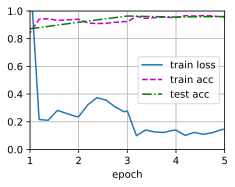

In [51]:
# # 5e-5 = 0.00005 Previously in textbook demo
train_fine_tuning(finetune_net, learning_rate=1e-4) 

loss 0.554, train acc 0.791, test acc 0.810
1412.3 examples/sec on [device(type='cuda', index=0)]


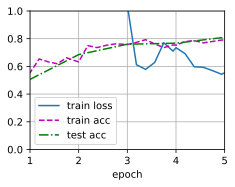

In [52]:
train_fine_tuning(finetune_net, learning_rate=1e-3) 

loss 1.515, train acc 0.630, test acc 0.741
1399.0 examples/sec on [device(type='cuda', index=0)]


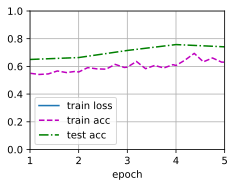

In [53]:
train_fine_tuning(finetune_net, learning_rate=1e-2) 

Exercise #2
* Experiment with the from-scratch version
* Increase number of epochs from 5 to 20 and increasing and decreasing the learning rate (1 value each, not a comprehensive hyperparameter sweep) results in slightly higher accuracies but still can't match the pre-trained + fine-tuned performance
    * Indicates superiority of pre-trained/foundation models

loss 0.294, train acc 0.883, test acc 0.841
1387.4 examples/sec on [device(type='cuda', index=0)]


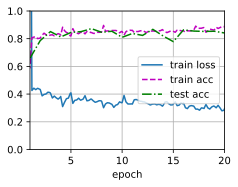

In [56]:
# Previous learning rate in textbook demo was 5e-4 = 0.0005
# Now using 1e-3 = 0.001 (double the previous learning rate)
# Also try much more epochs (5 previous, 20 now)
scratch_net = torchvision.models.resnet18() # No pre-trained weights
scratch_net.fc = nn.Linear(scratch_net.fc.in_features, 2)
train_fine_tuning(scratch_net, learning_rate=1e-3, num_epochs=20, param_group=False) 

loss 0.358, train acc 0.847, test acc 0.850
1393.7 examples/sec on [device(type='cuda', index=0)]


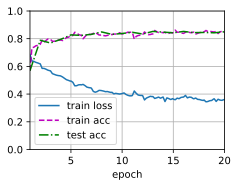

In [57]:
# Previous learning rate in textbook demo was 5e-4 = 0.0005
# Now using much smaller one of 1e-5 = 0.00001
# Also try much more epochs (5 previous, 20 now)
scratch_net = torchvision.models.resnet18() # No pre-trained weights
scratch_net.fc = nn.Linear(scratch_net.fc.in_features, 2)
train_fine_tuning(scratch_net, learning_rate=1e-5, num_epochs=20, param_group=False) 

Exercise #3
* Previously:
    * Val Acc: 94%
* Now, with source model parameters frozen
    * Val Acc: 88.6%
* Makes sense that Val Acc is lower with source model weights frozen, as they are not allowed to adjust for the task at hand

loss 0.712, train acc 0.827, test acc 0.886
1792.0 examples/sec on [device(type='cuda', index=0)]


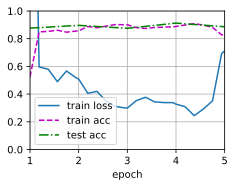

In [60]:
finetune_net = torchvision.models.resnet18(pretrained=True)

for param in finetune_net.parameters():
    param.requires_grad = False

finetune_net.fc = nn.Linear(finetune_net.fc.in_features, 2)

train_fine_tuning(finetune_net, learning_rate=5e-5)

Exercise #4
* Could just try copying the original weights for 512 out channels to the hotdog category to the "hotdog" category of our fine-tuned model
* Previously Val Acc: 94%
* Now Val Acc: 92.5%

loss 0.191, train acc 0.933, test acc 0.925
1371.6 examples/sec on [device(type='cuda', index=0)]


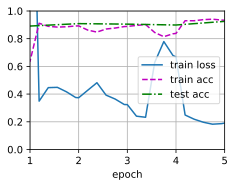

In [63]:
finetune_net = torchvision.models.resnet18(pretrained=True)
weight = pretrained_net.fc.weight # Read out original FC weights for "hotdog"
hotdog_w = torch.split(weight.data, 1, dim=0)[934]
hotdog_w.shape #, hotdog_w

# Replace the last layer with a new one for binary classification
finetune_net.fc = nn.Linear(finetune_net.fc.in_features, 2)

# Initialize the weights of new layer randomly, and then overwrite the weight for "hotdog" class with the pretrained ones
nn.init.xavier_uniform_(finetune_net.fc.weight)
finetune_net.fc.weight.data[1] = hotdog_w
train_fine_tuning(finetune_net, learning_rate=5e-5)


# 14.3 Object Detection and Bounding Boxes

In [37]:
%matplotlib inline
import torch
from d2l import torch as d2l

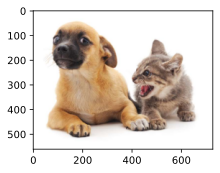

In [38]:
d2l.set_figsize()
img = d2l.plt.imread('../img/catdog.jpg')
d2l.plt.imshow(img)

### 14.3.1 Bounding Boxes

* Describe spatial location of object
* Rectangular box characterized by: 
    * $x, y$ coordinates of say upper-left and lower-right corner 
    * $(x,y)$ coodinates of the bounding box center, and the width and height of the box
* Defined below are functions to convert between the 2 parametrisizations for the bounding boxes 

In [38]:
def box_corner_to_center(boxes):
    """
    Convert incoming bounding boxes from corner format (x1, y1, x2, y2) to center format (cx, cy, w, h)
    Incoming inputs are of format (num_boxes, 4) where each row is (x1, y1, x2, y2)
    """
    x1, y1, x2, y2 = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2
    w = x2 - x1
    h = y2 - y1
    boxes = torch.stack((cx, cy, w, h), axis=1)
    return boxes

def box_center_to_corner(boxes):
    """
    Incoming arguments are of format (num_boxes, 4) where each row is (cx, cy, w, h)
    Convert incoming bounding boxes from center format (cx, cy, w, h) to corner format (x1, y1, x2, y2)
    """
    cx, cy, w, h = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    x1 = cx - 0.5 * w
    y1 = cy - 0.5 * h
    x2 = cx + 0.5 * w
    y2 = cy + 0.5 * h
    boxes = torch.stack((x1, y1, x2, y2), axis=-1)
    return boxes

In [42]:
# NOTE: Coordinates here are calculated from the book im guessing by "eyeballing it". 
# This section is just concept of bounding boxes, so IDT its semantic segmentation or anything like that
# Here `bbox` is the abbreviation for bounding box
dog_bbox, cat_bbox = [60.0, 45.0, 378.0, 516.0], [400.0, 112.0, 655.0, 493.0]

# Test the functinos give us the same corresponding box
boxes = torch.tensor((dog_bbox, cat_bbox))

# Function and its inverse gives us same original box back
box_center_to_corner( box_corner_to_center(boxes) ) == boxes

tensor([[True, True, True, True],
        [True, True, True, True]])

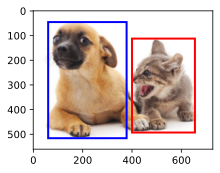

In [ ]:
def bbox_to_rect(bbox, color):
    """Convert bounding box to matplotlib format. To overlay on image. """
    # Convert the bounding box (upper-left x, upper-left y, lower-right x,
    # lower-right y) format to the matplotlib format: ((upper-left x,
    # upper-left y), width, height)
    return d2l.plt.Rectangle(
        xy=(bbox[0], bbox[1]), width=bbox[2]-bbox[0], height=bbox[3]-bbox[1],
        fill=False, edgecolor=color, linewidth=2)

fig = d2l.plt.imshow(img)
fig.axes.add_patch(bbox_to_rect(dog_bbox, 'blue'))
fig.axes.add_patch(bbox_to_rect(cat_bbox, 'red'))

### 14.3.2 Summary

* Object detection not only recgonizes what object it is, but where it is spatially. Position is represented by an overlaying bounding box on the image
* Two different representations for the bounding box, 2 corners and center + height/width

### 14.3.3 Exercises

1. Find another image and try to label a bounding box that contains the object. Compare labeling bounding boxes and categories: which usually takes longer?
1. Why is the innermost dimension of the input argument `boxes` of `box_corner_to_center` and `box_center_to_corner` always 4?

Exercise #1
* Skip. Labeling bounding boxes would take longer than simply classifing/labeling the image

Exercise #2
* Innermost dimension of input argument of `boxes` to both `box_corner_to_corner` and `box_center_to_center` is both 4 since to represent a rectangle since that would be the minimum amount of numbers needed to represent a specific rectangle. Probably some more formal proof in group theory or smth like that rather than back-of-hand intuition argument

# 14.4 Anchor Boxes

* Object detection algos usually samply a large number of regins in the input image and determine whether these regions contain objects of interest, and then adjust the boundaries of the reiongs so as to predict the _ground-truth bounding boxes_ of the boxes more accurately
* Many different regions-sampling schemes
* Anchor Boxes - Region Sampling Scheme
    * Generate multiple bounding boxes with varying scales and aspect ratios centered on each pixel
    * Resultant boxes are called _anchor boxes_

https://docs.pytorch.org/docs/2.12/generated/torch.set_printoptions.html
* Set options for printing. Items shamelessly taken from NumPy

Parameters/Arguments
* precision – Number of digits of precision for floating point output (default = 4).
* threshold – Total number of array elements which trigger summarization rather than full repr (default = 1000).
* edgeitems – Number of array items in summary at beginning and end of each dimension (default = 3).
* linewidth – The number of characters per line for the purpose of inserting line breaks (default = 80). Thresholded matrices will ignore this parameter.
* profile – Sane defaults for pretty printing. Can override with any of the above options. (any one of default, short, full)
* sci_mode – Enable (True) or disable (False) scientific notation. If None (default) is specified, the value is defined by torch._tensor_str._Formatter. This value is automatically chosen by the framework.

In [47]:
%matplotlib inline
import torch
from d2l import torch as d2l

torch.set_printoptions(2)  

### 14.4.1 Generating Multiple Anchor Boxes
* Suppose input image has height $h$ and width $w$
* Will be generated anchor boxes with different shapes centered on each pixel of images
    * Scale: $s \in (0, 1]$
    * Aspect Ratio: $r>0$ (ratio of width to height)
* Thus, width and height of anchor boxes would respectively be: $ws\sqrt{r}$ and $\frac{hs}{\sqrt{r}}$
* To generate multple anchor boxes with different shapes, set a series of scales $(s_1, \dots , s_n)$ and a series of aspect ratios $(r_1, \dots , r_n)$
    * If we were to use every possible combination of $r, s$ on each pixel, then that would result in $whnm$ anchor boxes. Altough this would cover all ground-truth bounding boxes, it is costly in computational cost
    * So in practice, we only consider combinations containing $s_1$ or $r_1$, like:
    $$ (s_1, r_1), (s_1, r_2), \dots, (s_1, r_m), (s_2, r_1), (s_3, r_1), \dots , (s_n, r_1)$$
    * This reduces the number of boxes we have to consider to $n + m - 1$ per pixel, so: $wh(n+m-1)$ anchor boxes overall

In [ ]:
import numpy as np

test_list = [1, 2, 3, 4, 5]
test_tuple = (1, 2, 3, 4, 5)
test_np_array = np.array([1, 2, 3, 4, 5])

list_tensor = torch.tensor(test_list)
tuple_tensor = torch.tensor(test_tuple)
np_array_tensor = torch.tensor(test_np_array)

list_tensor, tuple_tensor, np_array_tensor

(tensor([1, 2, 3, 4, 5]),
 tensor([1, 2, 3, 4, 5]),
 tensor([1, 2, 3, 4, 5], dtype=torch.int32))

In [65]:
torch.arange(5)

tensor([0, 1, 2, 3, 4])

In [ ]:
in_height = 96
in_width  = 128

sizes = [0.3, 0.6, 0.7]
size_tensor  = torch.tensor(sizes)
ratio_tensor = torch.tensor([1.0, 1.5, 2.0])

boxes_per_pixel = len(sizes) + len(ratio_tensor) - 1

steps_h, steps_w = 1/in_height, 1/in_width
offset_h, offset_w = 0.5, 0.5

center_h = (torch.arange(in_height) + offset_h) * steps_h
center_w = (torch.arange(in_width) + offset_w) * steps_w
shift_y, shift_x = torch.meshgrid(center_h, center_w, indexing='ij')
print(shift_y, shift_x, shift_y.shape, shift_x.shape)

shift_y = shift_y.reshape(-1)
shift_x = shift_x.reshape(-1)
print(shift_y, shift_x, shift_y.shape, shift_x.shape)

tensor([[0.0052, 0.0052, 0.0052,  ..., 0.0052, 0.0052, 0.0052],
        [0.0156, 0.0156, 0.0156,  ..., 0.0156, 0.0156, 0.0156],
        [0.0260, 0.0260, 0.0260,  ..., 0.0260, 0.0260, 0.0260],
        ...,
        [0.9740, 0.9740, 0.9740,  ..., 0.9740, 0.9740, 0.9740],
        [0.9844, 0.9844, 0.9844,  ..., 0.9844, 0.9844, 0.9844],
        [0.9948, 0.9948, 0.9948,  ..., 0.9948, 0.9948, 0.9948]]) tensor([[0.0039, 0.0117, 0.0195,  ..., 0.9805, 0.9883, 0.9961],
        [0.0039, 0.0117, 0.0195,  ..., 0.9805, 0.9883, 0.9961],
        [0.0039, 0.0117, 0.0195,  ..., 0.9805, 0.9883, 0.9961],
        ...,
        [0.0039, 0.0117, 0.0195,  ..., 0.9805, 0.9883, 0.9961],
        [0.0039, 0.0117, 0.0195,  ..., 0.9805, 0.9883, 0.9961],
        [0.0039, 0.0117, 0.0195,  ..., 0.9805, 0.9883, 0.9961]]) torch.Size([96, 128]) torch.Size([96, 128])
tensor([0.0052, 0.0052, 0.0052,  ..., 0.9948, 0.9948, 0.9948]) tensor([0.0039, 0.0117, 0.0195,  ..., 0.9805, 0.9883, 0.9961]) torch.Size([12288]) torch.Size([12

In [99]:
w = torch.cat((size_tensor * torch.sqrt(ratio_tensor[0]), sizes[0] * torch.sqrt(ratio_tensor[1:]))) * in_height / in_width
h = torch.cat((size_tensor / torch.sqrt(ratio_tensor[0]), sizes[0] * torch.sqrt(ratio_tensor[1:])))
print("h, w is: ", h, w)

h, w is:  tensor([0.3000, 0.6000, 0.7000, 0.3674, 0.4243]) tensor([0.2250, 0.4500, 0.5250, 0.2756, 0.3182])


In [100]:
torch.stack((-w, -h, w, h))

tensor([[-0.2250, -0.4500, -0.5250, -0.2756, -0.3182],
        [-0.3000, -0.6000, -0.7000, -0.3674, -0.4243],
        [ 0.2250,  0.4500,  0.5250,  0.2756,  0.3182],
        [ 0.3000,  0.6000,  0.7000,  0.3674,  0.4243]])

In [101]:
torch.stack((-w, -h, w, h)).T

tensor([[-0.2250, -0.3000,  0.2250,  0.3000],
        [-0.4500, -0.6000,  0.4500,  0.6000],
        [-0.5250, -0.7000,  0.5250,  0.7000],
        [-0.2756, -0.3674,  0.2756,  0.3674],
        [-0.3182, -0.4243,  0.3182,  0.4243]])

In [107]:
torch.stack((-w, -h, w, h)).T.repeat(in_height * in_width, 1) / 2, torch.stack((-w, -h, w, h)).T.repeat(in_height * in_width, 1).shape

(tensor([[-0.1125, -0.1500,  0.1125,  0.1500],
         [-0.2250, -0.3000,  0.2250,  0.3000],
         [-0.2625, -0.3500,  0.2625,  0.3500],
         ...,
         [-0.2625, -0.3500,  0.2625,  0.3500],
         [-0.1378, -0.1837,  0.1378,  0.1837],
         [-0.1591, -0.2121,  0.1591,  0.2121]]),
 torch.Size([61440, 4]))

In [108]:
torch.stack([shift_x, shift_y, shift_x, shift_y], dim=1), torch.stack([shift_x, shift_y, shift_x, shift_y], dim=1).shape

(tensor([[0.0039, 0.0052, 0.0039, 0.0052],
         [0.0117, 0.0052, 0.0117, 0.0052],
         [0.0195, 0.0052, 0.0195, 0.0052],
         ...,
         [0.9805, 0.9948, 0.9805, 0.9948],
         [0.9883, 0.9948, 0.9883, 0.9948],
         [0.9961, 0.9948, 0.9961, 0.9948]]),
 torch.Size([12288, 4]))

In [109]:
torch.stack([shift_x, shift_y, shift_x, shift_y], dim=1).repeat_interleave(boxes_per_pixel, dim=0), torch.stack([shift_x, shift_y, shift_x, shift_y], dim=1).repeat_interleave(boxes_per_pixel, dim=0).shape

(tensor([[0.0039, 0.0052, 0.0039, 0.0052],
         [0.0039, 0.0052, 0.0039, 0.0052],
         [0.0039, 0.0052, 0.0039, 0.0052],
         ...,
         [0.9961, 0.9948, 0.9961, 0.9948],
         [0.9961, 0.9948, 0.9961, 0.9948],
         [0.9961, 0.9948, 0.9961, 0.9948]]),
 torch.Size([61440, 4]))

In [121]:
tensor = torch.arange(4)
stack_dim0 = torch.stack([tensor, tensor, tensor], dim=0)
stack_dim1 = torch.stack([tensor, tensor, tensor], dim=1)


print(tensor, tensor.shape)
print(stack_dim0)
print(stack_dim1)


tensor([0, 1, 2, 3]) torch.Size([4])
tensor([[0, 1, 2, 3],
        [0, 1, 2, 3],
        [0, 1, 2, 3]])
tensor([[0, 0, 0],
        [1, 1, 1],
        [2, 2, 2],
        [3, 3, 3]])


In [122]:
stack_dim2 = torch.stack([tensor, tensor, tensor], dim=2)
print(stack_dim2)

IndexError: Dimension out of range (expected to be in range of [-2, 1], but got 2)

In [ ]:
# Example walkthrough of dimensions
N = in_height * in_width      # number of center points
B = boxes_per_pixel           # number of anchor shapes per center

# Goal is to create total of N * B anchor boxes
N * B

# for each center point:
#    create B anchor boxes

# So both tensors (center coordinates, anchor boxes coordinates) should end up with shape (N * B, 4) 
# where each row corresponds to an anchor box given by [x_min, y_min, x_max, y_max]
(N * B, 4)
[x_min, y_min, x_max, y_max]
 
# SHAPE OF anchor_manipulations
torch.stack((-w, -h, w, h))/2
# RECALL: w, h are generated from:
    # w = torch.cat((size_tensor * torch.sqrt(ratio_tensor[0]), sizes[0] * torch.sqrt(ratio_tensor[1:]))) * in_height / in_width  # Handle rectangular inputs
    # h = torch.cat((size_tensor / torch.sqrt(ratio_tensor[0]), sizes[0] / torch.sqrt(ratio_tensor[1:])))
# Will result in stacking along dimension 0 by default, which will result in:
    # tensor([-w], 
    #        [-h],
    #        [w],
    #        [h])
    # of dimensions (4, n + m - 1) 
    # RECALL: B = boxes_per_pixel = n + m - 1
# coordinates are given by -w/2, -h/2, w/2, h/2 because these are supposed to be w.r.t. box centers
# Dimensions will be: (4, B)

torch.stack((-w, -h, w, h)).T / 2
# Seems like stacking along dim=0 and transposing will result in same thing as just stacking 
# along dim=1, if the thing that is being stacked are 1D tensors
# Dimensions will be: (B, 4) at this point

torch.stack((-w, -h, w, h)).T.repeat(in_height * in_width, 1) / 2
# Repeat N = in_height * in_width times. The "1" indicates to repeat once along the corresponding dimension
# Dimensions will be: (N * B, 4) at this point, matching the shape of out_grid

# SHAPE OF out_grid
out_grid = torch.stack([shift_x, shift_y, shift_x, shift_y], dim=1)
# would have shape of (N, 4) since shift_x, shift_y were generated from: meshgrid(arange(in_height), arange(in_width)), 
# so will be dimensions of: N = in_height * in_width
    # stacking along dim=0: Stacks the tensors specified in args just on top of each other
    # stacking along dim=1: Stacks the tensors specified in args by order of arguments (groups 1st elements together, then groups 2nd elements together, ...)
        # Notice - this is what we are after since we wants shifts for each 4 coordinates into a single iterable/group 
        # corresponding to each anchor box

out_grid = torch.stack([shift_x, shift_y, shift_x, shift_y], dim=1).repeat_interleave(boxes_per_pixel, dim=0)
# .repeat_interleave: Repeats each element of the tensor along the specified dimension
# dimension=0 corresponds to each anchor box, so will repeat each anchor box's shifts X times, where
# X is the number of boxes there are per center
# will result in dimensions of (N * B, 4)


# output = out_grid + anchor_manipulations
# result in (N * B, 4) anchor box coordinates where 4 corresponds to 
# [x_min, y_min, x_max, y_max] = (x_center - w/2, y_center - h/2, x_center + w/2, y_center + h/2)

61440

In [123]:
def multibox_prior(data, sizes, ratios):
    """Generate anchor boxes with different shapes centered on each pixel.
    Note: sizes and ratios can be list, tuple, numpy array, or single float as they can all be
    converted to PyTorch tensors.

    Args:
        data: Input tensor of shape (batch_size, channels, height, width).
        sizes: List of anchor box sizes.
        ratios: List of anchor box aspect ratios.

    Returns:
        Tensor of shape (1, num_anchors, 4) containing the anchor boxes.
    """
    in_height, in_width = data.shape[-2:]
    device, num_sizes, num_ratios = data.device, len(sizes), len(ratios)
    boxes_per_pixel = (num_sizes + num_ratios - 1)
    size_tensor = torch.tensor(sizes, device=device)
    ratio_tensor = torch.tensor(ratios, device=device)

    # Offsets are required to move the anchor to the center of a pixel. Since
    # a pixel has height=1 and width=1, we choose to offset our centers by 0.5
    offset_h, offset_w = 0.5, 0.5
    steps_h = 1.0 / in_height  # Scaled steps in y axis
    steps_w = 1.0 / in_width  # Scaled steps in x axis

    # Generate all center points for the anchor boxes
    center_h = (torch.arange(in_height, device=device) + offset_h) * steps_h
    center_w = (torch.arange(in_width, device=device) + offset_w) * steps_w
    shift_y, shift_x = torch.meshgrid(center_h, center_w, indexing='ij')
    shift_y, shift_x = shift_y.reshape(-1), shift_x.reshape(-1)

    # Generate `boxes_per_pixel` number of heights and widths that are later
    # used to create anchor box corner coordinates (xmin, xmax, ymin, ymax)
    w = torch.cat((size_tensor * torch.sqrt(ratio_tensor[0]),
                   sizes[0] * torch.sqrt(ratio_tensor[1:])))\
                   * in_height / in_width  # Handle rectangular inputs
    h = torch.cat((size_tensor / torch.sqrt(ratio_tensor[0]),
                   sizes[0] / torch.sqrt(ratio_tensor[1:])))
    
    # Divide by 2 to get half height and half width
    anchor_manipulations = torch.stack((-w, -h, w, h)).T.repeat(
                                        in_height * in_width, 1) / 2

    # Each center point will have `boxes_per_pixel` number of anchor boxes, so
    # generate a grid of all anchor box centers with `boxes_per_pixel` repeats
    out_grid = torch.stack([shift_x, shift_y, shift_x, shift_y], dim=1).repeat_interleave(boxes_per_pixel, dim=0)
    output = out_grid + anchor_manipulations

    # https://docs.pytorch.org/docs/2.12/generated/torch.unsqueeze.html 
    # Add batch dimension
    return output.unsqueeze(0) 

img = d2l.plt.imread('../img/catdog.jpg')
h, w = img.shape[:2]

print(h, w, img.shape)
X = torch.rand(size=(1, 3, h, w))  # Construct input data
sizes = [0.75, 0.5, 0.25]
ratios = [1, 2, 0.5]
Y = multibox_prior(X, sizes=sizes, ratios=ratios)
print("Y.shape:", Y.shape)

print("h times w times boxes_per_pixel:", h * w * (len(sizes) + len(ratios) - 1))
print("Y", Y)

561 728 (561, 728, 3)
Y.shape: torch.Size([1, 2042040, 4])
h times w times boxes_per_pixel: 2042040
Y tensor([[[-0.2883, -0.3741,  0.2897,  0.3759],
         [-0.1920, -0.2491,  0.1933,  0.2509],
         [-0.0956, -0.1241,  0.0970,  0.1259],
         ...,
         [ 0.9030,  0.8741,  1.0956,  1.1241],
         [ 0.5906,  0.7339,  1.4080,  1.2643],
         [ 0.7950,  0.4688,  1.2037,  1.5294]]])


In [124]:
# Reshape to: (image_height, image_width, num_boxes_centered_at_pixel, 4_coordinates_per_box)
boxes = Y.reshape(h, w, 5, 4)

# Access first, last (fifth) anchor box centered at pixel (250, 250)
# Returns: (xmin, ymin, xmax, ymax)
boxes[250, 250, 0, :], boxes[250, 250, 4, :]

(tensor([0.0551, 0.0715, 0.6331, 0.8215]),
 tensor([ 0.1398, -0.0838,  0.5484,  0.9769]))

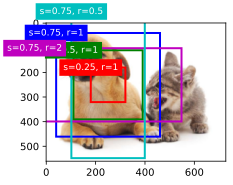

In [ ]:
def show_bboxes(axes, bboxes, labels=None, colors=None):
    """Show multiple bounding boxes overlaid on the image.
    
    args:
        axes: The matplotlib axes object to draw on.
        bboxes: A list of bounding boxes to display.
        labels: A list of labels for each bounding box.
        colors: A list of colors for each bounding box.
    """

    def make_list(obj, default_values=None):
        if obj is None:
            obj = default_values
        elif not isinstance(obj, (list, tuple)):
            obj = [obj]
        return obj

    labels = make_list(labels)
    colors = make_list(colors, ['b', 'g', 'r', 'm', 'c'])
    for i, bbox in enumerate(bboxes):
        color = colors[i % len(colors)]
        rect = d2l.bbox_to_rect(bbox.detach().numpy(), color)
        axes.add_patch(rect)
        if labels and len(labels) > i:
            text_color = 'k' if color == 'w' else 'w'
            axes.text(rect.xy[0], rect.xy[1], labels[i],
                      va='center', ha='center', fontsize=9, color=text_color,
                      bbox=dict(facecolor=color, lw=0))
            
d2l.set_figsize()
bbox_scale = torch.tensor((w, h, w, h))
fig = d2l.plt.imshow(img)
show_bboxes(fig.axes, boxes[250, 250, :, :] * bbox_scale, # Needed since bounding box coordinates are normalized. Need to rescale them for proper display on "unnormalized image"
            ['s=0.75, r=1', 's=0.5, r=1', 's=0.25, r=1', 's=0.75, r=2',
             's=0.75, r=0.5'])

### 14.4.2 Intersection over Union (IoU)
* Mentioned earlier that an ahchor box "well" surrounds the dog in the image
* If the ground truth bounding box of an object is known, then how do we quantify "well" here?
* Similarity score between anchor box and ground-truth bounding box by _Jaccard index_ where we measure similarity between two sets:
    * Given sets $\mathcal{A}$ and $\mathcal{B}$, the Jaccard index is defined as the size of intersection divided by size of their union
    * 0 means no overlap at all, 1 means perfect overlap (2 boxes are equal)
$$J(\mathcal{A}, \mathcal{B}) = \frac{|\mathcal{A} \cap \mathcal{B}|}{|\mathcal{A} \cup \mathcal{B}|}$$
    

In [155]:
# Walkthrough of box_iou 
# Recall, boxes are returned from multibox_prior (or specificed from ground-truth bounding boxes) as
# (x_min, y_min, x_max, y_max) format
boxes1 = torch.tensor([[0.00, 0.10, 0.2, 0.3], 
                       [0.15, 0.25, 0.4, 0.6]])
# Areas: (0.2 * 0.2) = 0.04, (0.25 * 0.35) = 0.0875
boxes2 = torch.tensor([[0.1, 0.15, 0.3, 0.4], 
                       [0.2, 0.25, 0.5, 0.7], 
                       [0.3, 0.35, 0.6, 0.8]])
# Areas: (0.2 * 0.25) = 0.05, (0.3 * 0.45) = 0.135, (0.3 * 0.45) = 0.135

def box_areas(boxes):
    """Compute areas for a list of normalized coordinates for bounding boxes"""
    box_areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return box_areas

areas1 = box_areas(boxes1)
areas2 = box_areas(boxes2)
print("Areas of boxes1:", areas1)
print("Areas of boxes2:", areas2)

# See difference between: 
# boxes1[:, :2] vs boxes1[:, None, :2]
# boxes2[:, :2] vs boxes2[:, None, :2]
print("boxes1 upperleft manipulatiions: \n",boxes1[:, :2], boxes1[:, :2].shape, "\n", boxes1[:, None, :2], boxes1[:, None, :2].shape)
print("boxes2 upperleft manipulatiions: \n",boxes2[:, :2], boxes2[:, :2].shape, "\n",boxes2[:, None, :2], boxes2[:, None, :2].shape)
print("boxes1 lower right manipulatiions: \n",boxes1[:, 2:], boxes1[:, 2:].shape, "\n", boxes1[:, None, 2:], boxes1[:, None, 2:].shape)
print("boxes2 lower right manipulatiions: \n",boxes2[:, 2:], boxes2[:, 2:].shape, "\n",boxes2[:, None, 2:], boxes2[:, None, 2:].shape)

# NOTICE, only the boxes1 coordinates insert a None for an extra dimension. This step is not applied
# to the boxes2 coordinates.

# Quick think about why min for lower right, and max for upper left. This would not change for ij or xy indexing
# NOTE: torch.max, torch.min would return the element-wise maximum and minimum of the input tensors. 
# Automatically handles where box1 has dominant horizontal but box2 has more dominant vertical
# NOTE: Only need extra dimension for boxes1 to enable broadcasting when subtracting it from boxes2

# UPPERLEFT for Intersection Calculstions
print("boxes1 upperleft: \n", boxes1[:, None, :2], boxes1[:, None, :2].shape)
print("boxes2 upperleft: \n", boxes2[:, :2], boxes2[:, :2].shape)

# LOWERRIGHT for Intersection Calculations
print("boxes1 lower right: \n", boxes1[:, None, 2:], boxes1[:, None, 2:].shape)
print("boxes2 lower right: \n", boxes2[:, 2:], boxes2[:, 2:].shape)

inter_upperlefts = torch.max(boxes1[:, None, :2], boxes2[:, :2]) # Pass None to to add new dimension
inter_lowerrights = torch.min(boxes1[:, None, 2:], boxes2[:, 2:])
# NOTE: Make sure to clamp to avoid negative values
inters = (inter_lowerrights - inter_upperlefts).clamp(min=0)

print("inter_upperlefts: \n", inter_upperlefts, inter_upperlefts.shape)
print("inter_lowerrights: \n", inter_lowerrights, inter_lowerrights.shape)
print("inters: \n", inters, inters.shape)

# First dimension of inters corresponds to boxes1  (since 2 boxes defined for boxes1), and 
# Second dimension of inters corresponds to boxes2 (since 3 boxes defined for boxes2)
# Read off as, for box1 in boxes1 (dimension 0), compute intersection 
# (by subtracting) from box2 in boxes2 (diven in dimension 1)

# At this point, inter_areas can be calculated by product of height and width of each box, which can be 
# accessed by accessing the [0] and [1] elements of every dim0 and dim1, so: 
inter_areas = inters[:, :, 0] * inters[:, :, 1]
print("inter_areas: \n", inter_areas, inter_areas.shape)

# Union areas
# areas1 and areas2 will have shape (num_boxes1) and (num_boxes2) respectively 
# inter_areas will have shape: (num_boxes1, num_boxes2) (SEE BELOW)
union_areas = areas1[:, None] + areas2 - inter_areas # A \union B = A + B - A ∩ B
print("areas1 broadcasted: \n", areas1[:, None], areas1[:, None].shape)
print("areas2: \n", areas2, areas2.shape)
print("\nareas1 + areas2: \n", areas1[:, None] + areas2, (areas1[:, None] + areas2).shape)
print("union_areas: \n", union_areas, union_areas.shape)

Areas of boxes1: tensor([0.0400, 0.0875])
Areas of boxes2: tensor([0.0500, 0.1350, 0.1350])
boxes1 upperleft manipulatiions: 
 tensor([[0.0000, 0.1000],
        [0.1500, 0.2500]]) torch.Size([2, 2]) 
 tensor([[[0.0000, 0.1000]],

        [[0.1500, 0.2500]]]) torch.Size([2, 1, 2])
boxes2 upperleft manipulatiions: 
 tensor([[0.1000, 0.1500],
        [0.2000, 0.2500],
        [0.3000, 0.3500]]) torch.Size([3, 2]) 
 tensor([[[0.1000, 0.1500]],

        [[0.2000, 0.2500]],

        [[0.3000, 0.3500]]]) torch.Size([3, 1, 2])
boxes1 lower right manipulatiions: 
 tensor([[0.2000, 0.3000],
        [0.4000, 0.6000]]) torch.Size([2, 2]) 
 tensor([[[0.2000, 0.3000]],

        [[0.4000, 0.6000]]]) torch.Size([2, 1, 2])
boxes2 lower right manipulatiions: 
 tensor([[0.3000, 0.4000],
        [0.5000, 0.7000],
        [0.6000, 0.8000]]) torch.Size([3, 2]) 
 tensor([[[0.3000, 0.4000]],

        [[0.5000, 0.7000]],

        [[0.6000, 0.8000]]]) torch.Size([3, 1, 2])
boxes1 upperleft: 
 tensor([[[0.0000, 

In [ ]:
boxes1[:, None, :2].shape = (2, 1, 2)
boxes2[:, :2].shape       = (3, 2)

# PyTorch aligns dimensions from the right side when broadcasting:
boxes1:   2   1   2
boxes2:       3   2

# PyTorch treats the missing leading dimension of boxes2 as 1
boxes1:   2   1   2
boxes2:   1   3   2
result:   2   3   2

In [156]:
def box_iou(boxes1, boxes2):
    """Compute pairwise IoU across two lists of anchor boxes and bounding boxes."""
    # x_max - x_min = width, y_max - y_min = height (tensor operations)
    box_area = lambda boxes: ((boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]))

    # Shape of `boxes1`, `boxes2`, `areas1`, `areas2`: (no. of boxes1, 4),
    # (no. of boxes2, 4), (no. of boxes1,), (no. of boxes2,)
    areas1 = box_area(boxes1)
    areas2 = box_area(boxes2)

    # Shape of `inter_upperlefts`, `inter_lowerrights`, `inters`: (no. of
    # boxes1, no. of boxes2, 2)
    # First ":" is for each box in boxes1/boxes2. The last :2 or 2: is for x and y coordinates of upper left and lower right corners
    # Recall: (x_min, y_min, x_max, y_max) format for boxes (check multibox_prior function comments)
    inter_upperlefts = torch.max(boxes1[:, None, :2], boxes2[:, :2]) # Pass None to to add new dimension
    inter_lowerrights = torch.min(boxes1[:, None, 2:], boxes2[:, 2:])
    inters = (inter_lowerrights - inter_upperlefts).clamp(min=0)
    # NOTE: torch.max, torch.min would return the element-wise maximum and minimum of the input tensors.
    # https://docs.pytorch.org/docs/2.12/generated/torch.clamp.html
    # .clamp() method: restricts all elements in a tensor to a specified minimum and maximum range. 
    # Values below the minimum are replaced by the minimum, values above the maximum are replaced by
    # the maximum, and values already within the bounds remain completely unchanged.

    # Shape of `inter_areas` and `union_areas`: (no. of boxes1, no. of boxes2)
    inter_areas = inters[:, :, 0] * inters[:, :, 1]
    union_areas = areas1[:, None] + areas2 - inter_areas # A \union B = A + B - A ∩ B
    return inter_areas / union_areas

### 14.4.3 Labeling Anchor Boxes in Training Data
* In a training dataset, we consider each anchor box as a training example
* To train an object detection model, we need a (1) class and (2) offset labels for each anchor box
    * Class: Class of the object relevant to the anchor box
    * Offset: Offset of the ground-truth bouding box relative to the anchor box
* During prediction, for each image we: 
    * Generate multiple anchor boxes
    * Predict the classes and offsets for all these anchor boxes
    * Adjust positions according to predicted offsets to obtain predicted bounding boxes
    * Output those predicted bounding boxes that satisfy certain criteria
* To label any generated anchor box, we refer to the labeled location and class of its assigned ground-truth bounding box that is closest to the anchor box. 
* Below in next section is algorithm for assigning closest ground-truth bounding boxes to anchor boxes

### 14.4.3.1 Assigning Ground Truth Bounding Boxes to Anchor Boxes
* Given an image, supposer there are:
    * $A_1, A_2, ... , A_{n_{a}}$: Anchor Boxes
    * $B_1, B_2, ... , B_{n_{b}}$: Ground-Truth Bounding Boxes
    * $n_a \geq n_b$
    * $X \in \mathbb{R}^{n_a \times n_b}$: Matrix where element $x_{ij}$ is the IoU of the anchor box $A_i$ and ground-truth bounding box $B_j$ where $i$ is the row and $j$ is the column index
1. Find largest element in matrix $X$ and denotes its row and column indices as $i_1$ and $i_j$ respectively
    1. Ground-truth bounding box $B_{j_1}$ is assigned to anchor box $A_{i_1}$
    1. Pairing is intuitive because $A_{i_1}$ and $B_{j_1}$ are closest among all pairs of anchor boxes and ground-truth bounding boxes
1. Find the largest of the remaining elements in matrix $X$ and denote its row and column indicies as $i_2$ and $j_2$ respectively. Assign ground truth box $B_{j_2}$ to anchor box $A_{i_2}$ and discard all the elements in the $i_2$ th column in matrix $X$. 
1. At this point, elements in two rows and two columns in matrix $X$ have been discarded. We proceed until all elements in $n_b$ columns in matrix $X$ are discarded. At this time, we have assigned a ground-truth bounding box to each of $n_b$ anchor boxes
1. Note that we only have $n_a - n_b$ anchor boxes remaining (unmatched). For any anchor box $A_i$, find the ground-truth bounding box $B_j$ with the largest IoU with $A_i$ throughout the i-th row of matrix $X$ and assign $B_j$ to $A_i$ ONLY IF this IoU is greater than a predefined threshold 

Walkthrough of example: 

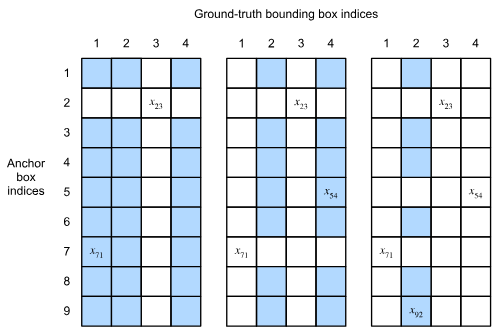

* Assuming that the max value of all elements in "original" matrix $X$ is $x_{23}$, we assign the ground-truth bounding box $B_3$ (since 3 is column index - which corresponds to ground-truth bounding box index) to anchor box $A_2$ (since 2 is row index - corresponds to anchor box index)
* Repeating this yields anchor box $A_7$ to $B_1$, $A_5$ to $B_4$, and $A_9$ to $B_2$. This Leaves $A_1, A_3, A_4, A_6, A_8$. We need to traverse through these remaining anchor boxes and determine whether to assign them to ground-truth bounding boxes according to a pre-defined threshold
* The algorithim described earlier and walked-through just above is implemented in **assign_anchor_to_bbox**


### 14.4.3.2 Labeling Classes and Offsets
* Now we cna label the class and offset for each anchor box 
* Suppose anchor box $A$ is assigned to ground-truth bounding box $B$. 
    * One one hand, class of anchor box $A$ will be labeled as that of $B$. 
    * On the other hand, the offset of anchor box $A$ will be labled according to the relative position between central coordinates of $B$ and $A$ together with relative size between these two boxes
* Given varying positions and sizes of different boxes in the dataset, we can apply transformations to those relative positions and sizes that may lead to more uniformly distributed offsets that are easier tof it. A common transformation is described below:
    * Suppose central coordinates of $A, B$ are $(x_a, y_a)$ and $(x_b, y_b)$, with respective widths and heights of $w_a, w_b, h_a, h_b$
    * Default values of constants below are:
        * $\mu_x = \mu_y = \mu_w = \mu_h = 0$
        * $\sigma_x = \sigma_y = 0.1$
        * $\sigma_w = \sigma_h = 0.2$ 
    * Define the offset of $A$ (w.r.t. $B$) as: 
$$ \left( \frac{\frac{x_b - x_a}{w_a} - \mu_x}{\sigma_x}, \frac{\frac{y_b - y_a}{h_a} - \mu_y}{\sigma_y} , \frac{\log{\frac{w_b}{w_a}} - \mu_w}{\sigma_w} , \frac{\log{\frac{h_b}{h_a} - \mu_h}}{\sigma_h}  \right)$$
* If an anchor box is not assigned a ground-truth bounding box, we just label the class of the anchor box as "background" 
    * Negative Anchor Boxes: Anchor boxes whose classes are background
    * Positive Anchor Boxes: Anchor boxes whose classes are assigned a ground-truth label (i.e. everything else)
* Below is implemented **multibox_target** function to label classes and offsets for anchor boxes (denoted by the **anchors** argument) using ground-truth bounding boxes (the **labels** argument). This function sets the background class to 0 and increments the indeger index of new class by 1

In [159]:
def assign_anchor_to_bbox(ground_truth, anchors, device, iou_threshold=0.5):
    """Assign closest ground-truth bounding boxes to anchor boxes.
    
    First assign ground-truth bounding boxes to anchor boxes based on IoU >= threshold.

    Second, ensure each ground-truth bounding box is assigned to an anchor box by finding the 
    anchor box with the highest IoU for each ground-truth bounding box.
    """
    num_anchors, num_gt_boxes = anchors.shape[0], ground_truth.shape[0]
    
    # Element x_ij in the i-th row and j-th column is the IoU of the anchor
    # box i and the ground-truth bounding box j
    # RECALL: box_iou() will return a tensor of shape (num_anchors, num_gt_boxes)
    jaccard = box_iou(anchors, ground_truth)
    
    # Initialize the tensor to hold the assigned ground-truth bounding box for
    # each anchor
    # 1D tensor of shape (num_anchors,) with a fill value of "-1" (corresponding to background, i.e. no ground-truth box assigned)
    anchors_bbox_map = torch.full((num_anchors,), -1, dtype=torch.long, device=device)

    # Assign ground-truth bounding boxes according to the threshold
    # Find and return tuple of (value, indices) of jaccard along each row, i.e. anchor boxes (dim=1)
    max_ious, indices = torch.max(jaccard, dim=1)

    # First, create binary boolean tensor to identify which anchors have IoU >= specified threshold of 
    # the same shape as max_ious: anchors.shape[0]. Then, return the indicies of the non-zero (i.e. True) 
    # which by default will be in 2D tensor format. We then reshape it to 1D by .reshape(-1)
    anc_i = torch.nonzero(max_ious >= iou_threshold).reshape(-1)

    # Return indices from earlier but with condition with boolean that returns True only if the IoU
    # is greater than or equal to the threshold
    box_j = indices[max_ious >= iou_threshold]

    # Assign ground-truth bounding boxes (represented by their indices where IoU exceeds threshold)
    # to the index of the anchor boxes to anchors_bbox_map. Indices/elements of anchors_bbox_map
    # that were not assigned any ground-truth bounding boxes will remain as -1
    anchors_bbox_map[anc_i] = box_j

    # Initialize tensor to fill in the jaccard matrix with -1 for already assigned boxes
    col_discard = torch.full((num_anchors, ), -1)
    row_discard = torch.full((num_gt_boxes,), -1)

    for _ in range(num_gt_boxes): # Run for each ground truth box to ensure each is assigned to an anchor. 
        max_idx = torch.argmax(jaccard)  # Find the largest IoU
        box_idx = (max_idx % num_gt_boxes).long()
        anc_idx = (max_idx / num_gt_boxes).long()
        anchors_bbox_map[anc_idx] = box_idx
        # Assigns all jaccard elements corresponding to the ground truth box to -1, given by the 
        # row (anc_idx) and column (box_idx) just used to find the maximum remaining/current IoU
        jaccard[:, box_idx] = col_discard  
        jaccard[anc_idx, :] = row_discard

    # Return a tensor of shape (num_anchors,) with the assigned ground-truth bounding box column indicies
    # and -1 for unassigned anchor boxes (background)
    return anchors_bbox_map 

In [157]:
# Example
# Without for loop in assign_anchor_to_bbox, could risk some unassigned ground-truth boxes
# Both anchor0 and anchor1 are assigned to gt0, while no anchor for gt2 because none of 
# its IoUs are above threshold of 0.5
             gt0    gt1
anchor0     0.60   0.10
anchor1     0.55   0.20
anchor2     0.30   0.40

IndentationError: unexpected indent (1445979656.py, line 3)

* Suppose Anchor A has center & size given by: $ (x_a, y_a, w_a, h_a)$
* Supposed Ground Truth B has center & size given by: $(x_b, y_b, w_b, h_b)$
* Raw geometric differences would be:
    * $x_b - x_a, y_b - y_a, w_b - w_a, h_b - h_a$
* Should normalize center shift by image size under consideration:
    * $ \frac{x_b - x_a}{w_a}, \frac{y_b - y_a}{h_a}$
* Shouldn't use same normalization as for center shift as height/width shifts because scaling is multiplicative. We should use log-scale ratio instead:
    * $ \log{\frac{w_b}{w_a}}, \log{\frac{h_b}{h_a}}$ 
    * This way, ground-truth box is twice as wide as anchor, that would give: $\log{2}$
    * This way, ground-truth box is half as wide as anchor, that would give: $- \log{2}$
* These 4 quantitues are standardized using means & std's. Default values are stated below:
    $$\left( \frac{ \frac{x_b - x_a}{w_a} - \mu_x }{\sigma_x}, \frac{ \frac{y_b - y_a}{h_a} - \mu_y }{\sigma_y}, \frac{ \log \frac{w_b}{w_a} - \mu_w }{\sigma_w}, \frac{ \log \frac{h_b}{h_a} - \mu_h }{\sigma_h}\right)$$
    * $\mu_x = \mu_y = \mu_w = \mu_h = 0$; $\sigma_x = \sigma_y = 0.1$; $\sigma_w, \sigma_h=0.2$
    $$ \left(10\frac{x_b-x_a}{w_a},\;10\frac{y_b-y_a}{h_a},\;5\log\frac{w_b}{w_a},\;5\log\frac{h_b}{h_a}\right)$$


In [ ]:
def offset_boxes(anchors, assigned_bb, eps=1e-6):
    """Transform for anchor box offsets."""
    c_anc         = d2l.box_corner_to_center(anchors)
    c_assigned_bb = d2l.box_corner_to_center(assigned_bb)
    offset_xy = 10 * (c_assigned_bb[:, :2] - c_anc[:, :2]) / c_anc[:, 2:]
    offset_wh = 5 * torch.log(eps + c_assigned_bb[:, 2:] / c_anc[:, 2:])

    # torch.cat along dim=1 just concatenates the offset_xy and offset_wh tensors to a long 1D tensor
    # Similar syntax/argument rules as torch.stack()
    offset = torch.cat([offset_xy, offset_wh], axis=1)
    return offset


def multibox_target(anchors, labels):
    """Label anchor boxes using ground-truth bounding boxes."""
    batch_size, anchors = labels.shape[0], anchors.squeeze(0)
    batch_offset       = []
    batch_mask         = []
    batch_class_labels = []

    device, num_anchors = anchors.device, anchors.shape[0]
    
    for i in range(batch_size):
        label = labels[i, :, :]
        anchors_bbox_map = assign_anchor_to_bbox(label[:, 1:], anchors, device)
        bbox_mask = ((anchors_bbox_map >= 0).float().unsqueeze(-1)).repeat(1, 4)
        # Initialize class labels and assigned bounding box coordinates with
        # zeros
        class_labels = torch.zeros(num_anchors, dtype=torch.long, device=device)
        assigned_bb = torch.zeros((num_anchors, 4), dtype=torch.float32, device=device)
        # Label classes of anchor boxes using their assigned ground-truth
        # bounding boxes. If an anchor box is not assigned any, we label its
        # class as background (the value remains zero)
        indices_true = torch.nonzero(anchors_bbox_map >= 0)
        bb_idx = anchors_bbox_map[indices_true]
        class_labels[indices_true] = label[bb_idx, 0].long() + 1
        assigned_bb[indices_true] = label[bb_idx, 1:]
        # Offset transformation
        offset = offset_boxes(anchors, assigned_bb) * bbox_mask
        batch_offset.append(offset.reshape(-1))
        batch_mask.append(bbox_mask.reshape(-1))
        batch_class_labels.append(class_labels)
    bbox_offset = torch.stack(batch_offset)
    bbox_mask = torch.stack(batch_mask)
    class_labels = torch.stack(batch_class_labels)
    return (bbox_offset, bbox_mask, class_labels)

### 14.4.3.3 An Example 
* Illustrate anchor box labeling via a concrete example. 
* Define ground-truth bounding boxes for the dog and cat in the loaded image, where first element is the class (0 for dog and 1 for cat) and the remaing 4 elements are the (x, y)-axis coordinates at upper-left and lower-right corners (where they range from 0 to 1 to indicate "how far along")
* Construct 5 anchor boxes to be labeled using the coordinates of the upper-left corner and the lower-right corner: $A_0, \dots, A_4$ (notice that the index starts from 0). Then, plot these ground-truth bounding boxnes and anchor boxes in the image

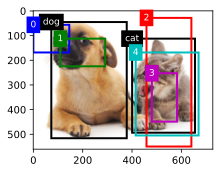

In [ ]:
ground_truth = torch.tensor([[0, 0.1, 0.08, 0.52, 0.92],
                             [1, 0.55, 0.2, 0.9, 0.88]])
anchors      = torch.tensor([[0, 0.1, 0.2, 0.3],       
                             [0.15, 0.2, 0.4, 0.4],
                             [0.63, 0.05, 0.88, 0.98], 
                             [0.66, 0.45, 0.8, 0.8],
                             [0.57, 0.3, 0.92, 0.9]])

fig = d2l.plt.imshow(img)
bbox_scale = torch.tensor((w, h, w, h)) # Coped from earlier. Need to rescale normalized coordinates
show_bboxes(fig.axes, ground_truth[:, 1:] * bbox_scale, ['dog', 'cat'], 'k')
show_bboxes(fig.axes, anchors * bbox_scale, ['0', '1', '2', '3', '4']);

using **multibox_target** function defined/implemented above, we can label classes and offsets of these anchor boxes based on the ground-truth bounding boxes for the dog and cat. In this particular example, indicies for the classes are: 
* Background = 0
* Dog = 1
* Cat = 2

Below, we add an dimensino for examples of anchor boxes and ground-truth bounding boxes. 

* There will be 3 items in "labels", all of which are in the tensor format. 
* 3rd Item contains the labeled classes of the input anchor boxes 
* Analysis of returned class labels based on anchor and gorund-truth boudning box positions in image
    * IoU of $A_4$ and cat's ground-truth bounding box is the largest, thus $A_4$ will ba labeled as cat (2)
        * Remove all other remaining pairs containing $A_4$ or ground-truth bounding box of the cat
    * Of the remaining pairs of anchor boxes, $A_1$ has the highest IoU with the bounding box of the dog $B_1$. Thus, we label $A_1$ as dof (class 1)
* We have 3 unlabeled/remaining anchor boxes: $A_0, A_2, A_3$
    * For $A_0$, the largest IoU is from the pairing with the ground-truth bounding box of the dog, but it is less than the pre-defined threshold of 0.5, so we label it as "background" (class 0)
    * For $A_2$, the class of the ground-truth bounding box with the largest IoU is the cat, and it exceeds the pre-defined threshold of 0.5, so we label it as "cat" (class 2)
    * For $A_3$, the largest IoU is from the pairing with the cat's ground-truth bounding box, but the IoU is less than the pre-defined value of 0.5, so we label it as "background" (class 0) 


* Labels[0]: Contains the 4 offset variables for each anchor box. Note that the offsets corresponding to negative-class anchor boxes are labeled as 0's
* Labels[1]: Mask variable of the shape (batch size, 4 times the number of anchor boxes (5 in this case) ). Every 4 elements in the mask variable correspond to the 4 offset variables of each anchor box. Since we do not care about background detection, offsets of this negative class should not affect the objective function. This is given by 0's in the mask variable filtering out negative class offsets before calculating the objective function. 
* Labels[2]: Class labels for each of the anchor boxes. Scheme of 0, 1, 2 is described above (background, dog, cat respectively)

In [ ]:
# Add dimension for examples of anchor boxes and ground-truth bounding boxes
labels = multibox_target(anchors.unsqueeze(dim=0), ground_truth.unsqueeze(dim=0))

print("Labels[0] (offsets for each anchor box):     \n", labels[0])
print("Labels[1] (mask for each anchor box):        \n", labels[1])
print("Labels[2] (class labels for each anchor box):\n", labels[2])

Labels[0] (offsets for each anchor box):     
 tensor([[-0.00e+00, -0.00e+00, -0.00e+00, -0.00e+00,  1.40e+00,  1.00e+01,
          2.59e+00,  7.18e+00, -1.20e+00,  2.69e-01,  1.68e+00, -1.57e+00,
         -0.00e+00, -0.00e+00, -0.00e+00, -0.00e+00, -5.71e-01, -1.00e+00,
          4.17e-06,  6.26e-01]])
Labels[1] (mask for each anchor box):        
 tensor([[0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 1., 1.,
         1., 1.]])
Labels[2] (class labels for each anchor box):
 tensor([[0, 1, 2, 0, 2]])


### 14.4.4 Predicting Bounding Boxes with Non-Maximum Suppression
* During prediction, we generate multiple anchor boxes for the image and predict the classes and offsets for each of them
* A predicted bounding box is obtained according to an anchor box w/ its predicted offset
* Below is an implemented of **offset_inverse** that takes in anchors and offset predictions as inputs and applies inverse offset transformations to return the predicted bounding box coordinates

In [66]:
def offset_inverse(anchors, offset_preds):
    """Predict bounding boxes based on anchor boxes with predicted offsets."""
    anc = d2l.box_corner_to_center(anchors)
    pred_bbox_xy = (offset_preds[:, :2] * anc[:, 2:] / 10) + anc[:, :2]
    pred_bbox_wh = torch.exp(offset_preds[:, 2:] / 5) * anc[:, 2:]
    pred_bbox = torch.cat((pred_bbox_xy, pred_bbox_wh), axis=1)
    predicted_bbox = d2l.box_center_to_corner(pred_bbox)
    return predicted_bbox

* In the case that there are many similar predicted bounding boxes (with significant overlap), they can potentially output for surrounding the same object
* To simplify the output, we can merge similar predicted bounding boxes that belong to the same object by using _non-maximum suppression (NMS)_.

* How Non-Maximum Suppression (NMS) Works:
    * For a predicted bounding box $B$, the object detection model calculates the predicted likelihood for each class
    * Denoting by $p$ the largest predicted liklihood, the class corresponding to this probability is the predicted class for $B$. 
    $ We refer to $p$ as the _confidence_ (score) of the predicted bounding box $B$
    * On the same image, all predicted non-background bounding boxes are sorted by confidence in descending order to generate a list $L$. The sorted list $L$ is then manipulated in the following steps:
        1. Select the predicted bounding box $B_1$ with the highest confidence from $L$ as a basis and remove all non-basis predicted bounding boxes whose IoU with $B_1$ exceeds a predefined threhsold $\epsilon$ from $L$. At this point, $L$ keeps the predicted bounding box with the highest confidence but drops other that are too similar to it (i.e. those with non-maximum confidence scores are suppressed)
        1. Select the predicted bounding box $B_2$ with the second highest confidence from $L$ as another basis and remove all non-basis predicted bounding boxes whose IoU with $B_2$ exceeds $\epsilon$ from $L$. 
        1. Repeat the above process until all the predicted bounding boxes in $L$ have been used as a basis. At this time, the IoU of any pair of predicted bounding boxes in $L$ is below the threshold $\epsilon$, thus no pair is too similar with each other
        1. Output all the predicted bounding boxes in the list $L$
* The following **nms** function sorts confidence scores in descending order and returns their indices
* We also define a **multibox_detection** function to apply non-maximum suppression to predicting bounding boxes

In [68]:
def nms(boxes, scores, iou_threshold):
    """Sort confidence scores of predicted bounding boxes in descending order and returns their indices."""
    B = torch.argsort(scores, dim=-1, descending=True)
    keep = []  # Indices of predicted bounding boxes that will be kept
    while B.numel() > 0:
        i = B[0]
        keep.append(i)
        if B.numel() == 1: break
        iou = box_iou(boxes[i, :].reshape(-1, 4),
                      boxes[B[1:], :].reshape(-1, 4)).reshape(-1)
        inds = torch.nonzero(iou <= iou_threshold).reshape(-1)
        B = B[inds + 1]
    return torch.tensor(keep, device=boxes.device)


def multibox_detection(cls_probs, offset_preds, anchors, nms_threshold=0.5,
                       pos_threshold=0.009999999):
    """Predict bounding boxes using non-maximum suppression."""
    device, batch_size = cls_probs.device, cls_probs.shape[0]
    anchors = anchors.squeeze(0)
    num_classes, num_anchors = cls_probs.shape[1], cls_probs.shape[2]
    out = []
    for i in range(batch_size):
        cls_prob, offset_pred = cls_probs[i], offset_preds[i].reshape(-1, 4)
        conf, class_id = torch.max(cls_prob[1:], 0)
        predicted_bb = offset_inverse(anchors, offset_pred)
        keep = nms(predicted_bb, conf, nms_threshold)
        # Find all non-`keep` indices and set the class to background
        all_idx = torch.arange(num_anchors, dtype=torch.long, device=device)
        combined = torch.cat((keep, all_idx))
        uniques, counts = combined.unique(return_counts=True)
        non_keep = uniques[counts == 1]
        all_id_sorted = torch.cat((keep, non_keep))
        class_id[non_keep] = -1
        class_id = class_id[all_id_sorted]
        conf, predicted_bb = conf[all_id_sorted], predicted_bb[all_id_sorted]
        # Here `pos_threshold` is a threshold for positive (non-background)
        # predictions
        below_min_idx = (conf < pos_threshold)
        class_id[below_min_idx] = -1
        conf[below_min_idx] = 1 - conf[below_min_idx]
        pred_info = torch.cat((class_id.unsqueeze(1),
                               conf.unsqueeze(1),
                               predicted_bb), dim=1)
        out.append(pred_info)
    return torch.stack(out)

* Apply above implementations to concrete example with 4 anchor boxes. For simplicity, assume that predicted offsets are all 0s. This means that the predicted bounding boxes are anchor boces
* For each class among the background, dog, cat, we also define its predicted likelihood
* We then plot these predicted bounding boxes with their confidence on the image

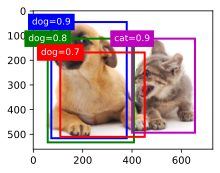

In [69]:
anchors = torch.tensor([[0.1, 0.08, 0.52, 0.92], [0.08, 0.2, 0.56, 0.95],
                      [0.15, 0.3, 0.62, 0.91], [0.55, 0.2, 0.9, 0.88]])
offset_preds = torch.tensor([0] * anchors.numel())
cls_probs = torch.tensor([[0] * 4,  # Predicted background likelihood
                      [0.9, 0.8, 0.7, 0.1],  # Predicted dog likelihood
                      [0.1, 0.2, 0.3, 0.9]])  # Predicted cat likelihood

fig = d2l.plt.imshow(img)
show_bboxes(fig.axes, anchors * bbox_scale,
            ['dog=0.9', 'dog=0.8', 'dog=0.7', 'cat=0.9'])

* We can then call the **multibox_detection** function to perform non-maximum suppression, where the threshold is set to 0.5
* NOTE - we add a dimension for examples in the tensor input
* We can see taht the shape of the returned result is: (batch size, number of anchor boxes, 6)
    * The 6 elements in the innermost dimension gives the output information for the same predicted bounding box
    * The 1st element is the predicted class index. Note, class indexes start from 0 (0 for dog, 1 for cat). Here, the value of -1 indicates background or removal in non-maximim suppression
    * 2nd element is the confidence of the predicted bounding box
    * Remaining 4 elements are the $(x, y)$ axis coordinates of the upper-left corner and the lower-right corner of the predicted bounding box, respectively (range is between 0 and 1)
* After removing those predicted bounding boxes of class $-1$, we can output the final predicted bounding box kepy by non-maximum suppression
* In practice, we can remove predicted bounding boxes with lower confidence even before performing on-maximum suppresion, thereby reducing computation in this algorithm. We may also post-process the output of non-maximum suppression, for example, by only keeping results with higher confidence in the final output

In [70]:
output = multibox_detection(cls_probs.unsqueeze(dim=0),
                            offset_preds.unsqueeze(dim=0),
                            anchors.unsqueeze(dim=0),
                            nms_threshold=0.5)
output

tensor([[[ 0.00,  0.90,  0.10,  0.08,  0.52,  0.92],
         [ 1.00,  0.90,  0.55,  0.20,  0.90,  0.88],
         [-1.00,  0.80,  0.08,  0.20,  0.56,  0.95],
         [-1.00,  0.70,  0.15,  0.30,  0.62,  0.91]]])

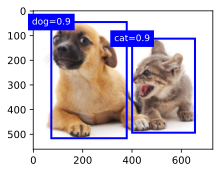

In [71]:
fig = d2l.plt.imshow(img)
for i in output[0].detach().numpy():
    if i[0] == -1:
        continue
    label = ('dog=', 'cat=')[int(i[0])] + str(i[1])
    show_bboxes(fig.axes, [torch.tensor(i[2:]) * bbox_scale], label)

### 14.4.5 Summary
* Generate anchor boxes with different shapes centered on each pixel of the image
* Intersection over Union (IoU) (a.k.a. Jaccard Index) measures the similarity of two bounding boxes. it is the ration of the intersection area to their union area
* In a training set, we need 2 types of labels for each anchor box. 
    1. Class of object relevant to the anchor box
    1. Offset of the ground-truth bounding box relative to the anchor box
* During prediction, we can use non-maximum suppression (NMS) to remove similar predicted bounding boxes, thereby simplifying the output

### 14.4.6 Exercises
1. Change values of `sizes` and `ratios` in the `multibox_prior` function. What are the changes to the generated anchor boxes?
1. Construct and visualize two bounding boxes with an IoU of 0.5. How do they overlap with each other?
1. Modify the variable `anchors` in 14.4.3 and 14.4.4. How do the results change?
1. Non-maximum suppression is a greedy algorithm that suppresses predicted bounding boxes by *removing* them. Is it possible that some of these removed ones are actually useful? How can this algorithm be modified to suppress *softly*? You may refer to Soft-NMS Bodla.Singh.Chellappa.ea.2017.
1. Rather than being hand-crafted, can non-maximum suppression be learned?

# 14.5 Multiscale Object Detection

* In 14.4, anchor boxes were generated on centers of pixels of an input image
* All these anchor boxes represent samples of different regions of the image
* We may end up with too many anchor boxes to compute if they are generated for every pixel
    * Consider the case of a $561 \times 728$ input image
    * If there are $5$ anchor boxes per pixel, there would be over 2 million anchor boxes $561 \times 728 \times 5$

### 14.5.1 Multiscale Anchor Boxes
* Easy to reduce anchor box count per image
* For example, can just uniformly saple a small portion of pixels to generate anchor boxes centered on them
* At different scales, we can generate different number of anchor boxes of different sizes
    * Intuitively, smaller boxes are more likely to appear on an image than larger ones
    * Consider a $2\times 2$ image. There are $4$ ways for a $1\times 1$ image to appear, 2 ways for $1\times 2$ images to appear, and $1$ way for a $2\times 2$ image to appear
    * Takeaway: When using smaller anchor boxes, we can sample more regions, and when using larger anchor boxes, we can smaple fewer regions
* Recall from Section 7.2 we call a 2d array output of a convolutional layer a "feature map". By defining the feature map shape, we can determine centers of uniformly sampled anchor boxes on any image
* Belwo a **display_anchors** function is defined and implemented
    * We generate anchor boxes (anchors) on the feature map (fmap) with each unit (pixel) as the anchor box center
    * Since the (x, y)-axis coordinate values in the anchor boxes (anchors) have been divided by the width and height of the feature map (fmap), these values are between 0 and 1 which indicate the relative positions of anchor boxes in the feature map
    * Since centers of the anchor boxes (anchors) are spread over all units on the feature map (fmap), these centers must be uniformly distributed on any input image in terms of their relative spatial positions
        * Given height and iwdth of the feature map (fmap_h & fmap_w), the following function will uniformly sample pixels in fmap_h rows and fmap_w columns on any input image
        * Centered on these uniformly sampled pixels, anchor boxes of scale $s$ (assuming the length of the list $s$ is 1) and different aspect ratios (ratios) will be generated

In [72]:
%matplotlib inline
import torch
from d2l import torch as d2l

img = d2l.plt.imread('../img/catdog.jpg')
h, w = img.shape[:2]
h, w

(561, 728)

In [73]:
def display_anchors(fmap_w, fmap_h, s):
    d2l.set_figsize()
    # Values on the first two dimensions do not affect the output
    fmap = torch.zeros((1, 10, fmap_h, fmap_w))
    anchors = d2l.multibox_prior(fmap, sizes=s, ratios=[1, 2, 0.5])
    bbox_scale = torch.tensor((w, h, w, h))
    d2l.show_bboxes(d2l.plt.imshow(img).axes, anchors[0] * bbox_scale)

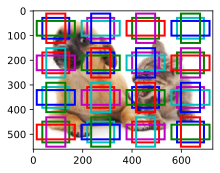

In [77]:
# Detection of small obects
# For clarity, anchor boxes with different centers that do not overlap. 
# Anchor box scale is set to 0.15 and height and width of the feature map are set ot 4 (corresponds to
# 4 independent rows and columns of anchor boxes)
display_anchors(fmap_w=4, fmap_h=4, s=[0.15])

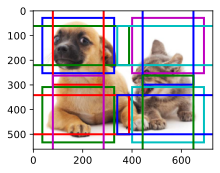

In [78]:
# Reduce  height & width of feature map to 2
# Use larger anchor boxes to detect larger objects. Scale is st to 0.4 which will result in 
# some overlap between anchor boxes
display_anchors(fmap_w=2, fmap_h=2, s=[0.4])

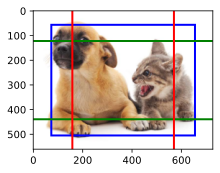

In [79]:
# Further reduce height and width of feature map by half (to 1) and increase the anchro box scale to 0.8
# Note that the center of the anchor box is the center of the image
display_anchors(fmap_w=1, fmap_h=1, s=[0.8])

### 14.5.2 Multiscale Detection

* Since we can generate multiscale anchor boxes, we can use them to detect objects of various sizes at different scales
* We introduce a CNN-based multi-scale object detection method that we will implement in Section 14.7
* At some scale, say that we have $c$ feature maps of shape $h\times w$
    * Using method in Section 14.5.1, we generate $hw$ sets of anchor boxes where each set has $a$ anchor boxes with the same center
    * Recall the first scale in the experiments in 14.5.1, where given 10 (number of channels) $4\times 4$ feature maps, we generate 16 sets of anchor boxes where each set contains 3 anchor boxes with the same center
    * Next, each anchor box is labeled with the class and offset based on ground-truth bounding box
    * At current scale, object detection models needs to predict the classes and offsets of $hw$ sets of anchor boxes on the input image, where different sets have different centers
* Assume that the $c$ feature maps here are the intermediate outputs obtained by the CNN forward propogation based on the input image
    * Since there are $hw$ different spatial positions on each feature map, the same spatial position can be thought of as having $c$ units
    * According to the definition of receptive field in Section 7.2, these $c$ units at the same sptatial position of the feature maps have the same receptive field on the input image - they represent the image input information in the same receptive field
    * Therefore, we can transform the $c$ units of the feature maps at the same spatial position into the classes and offsets of the $a$ anchor boxes generated using this spatial potiion
    * Essentially, we use the informatino of the input image in a certain receptive field to predict the classes and offsets of the anchor boxes that are close to that receptive field on the input image
* When feature maps at different layers have varying-size receptive fields on the input image, hey can eb used to detect objects of different sizes
    * e.g. we can design a neural network where units of feature maps that are closer to the output layer have wider receptive fields so they can detect larger objects from the input image
* Takeaway: We can leverage layerwise representations of images at multiple levels by deep neural networks for multiscale object detection. A concrete example will be shown in Section 14.7

### 14.5.3 Summary
* At multple scales, we can generate anchor boxes with different sizes to detect objects with different sizes
* By defining the shapes of feature maps, we can determine centers of uniformly sampled anchor boxes on any image
* We use the informatino of the input image in a certain receptive field to predict the classes and offsets of the anchor boxes that are close to that receptive field on the input image
* Through deep learning, we can leverage its layerwise representations of images at multiple levels for multiscale object detection

### 14.5.4 Exercises
1. According to our discussions in AlexNet section, deep neural networks learn hierarchical features with increasing levels of abstraction for images. In multiscale object detection, do feature maps at different scales correspond to different levels of abstraction? Why or why not?
1. At the first scale (`fmap_w=4, fmap_h=4`) in the experiments in 14.5.1, generate uniformly distributed anchor boxes that may overlap.
1. Given a feature map variable with shape $1 \times c \times h \times w$, where $c$, $h$, and $w$ are the number of channels, height, and width of the feature maps, respectively. How can you transform this variable into the classes and offsets of anchor boxes? What is the shape of the output?

# 14.6 The Object Detection Dataset
* Note, unlike MNIST or Fashion-MNIST, there is no small dataset for object detection
* For demonstrative/educational purposes, d2l authors collected and labeled small dataset of 1000 banana images with different rotations and sizes
* Placed each banana image at random positon in background image. Also added labeled bounding boxes for all bananas in images

### 14.6.1 Downloading the Dataset
* Dataset can be directly downded from interet
* Contains csv label files and images themselves

In [81]:
%matplotlib inline
import os
import pandas as pd
import torch
import torchvision
from d2l import torch as d2l

d2l.DATA_HUB['banana-detection'] = (
    d2l.DATA_URL + 'banana-detection.zip',
    '5de26c8fce5ccdea9f91267273464dc968d20d72')

### 14.6.2 Reading the Dataset
* Dataset includes a csv file for object classes and ground-truth bounding box coordinates corresponding to the upper-left & lower-right corners
* The **read_data_bananas** funciton will be defined and used to read images and labels
* **BananasDataset** class will allow us to create a customized **Dataset** instance for loading the banana detection dataset: https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html
* Define **load_data_bananas** to return 2 data iterator instance for both training and test sets
    * Note - for test dataset, there is no need to read it in random order. For training, needed for "S"GD

In [ ]:
def read_data_bananas(is_train=True):
    """Read the banana detection dataset images and labels."""
    data_dir = d2l.download_extract('banana-detection')
    csv_fname = os.path.join(data_dir, 'bananas_train' if is_train
                             else 'bananas_val', 'label.csv')
    csv_data = pd.read_csv(csv_fname)
    csv_data = csv_data.set_index('img_name')
    images, targets = [], []
    for img_name, target in csv_data.iterrows():
        images.append(torchvision.io.read_image(
            os.path.join(data_dir, 'bananas_train' if is_train else
                         'bananas_val', 'images', f'{img_name}')))
        # Here `target` contains (class, upper-left x, upper-left y,
        # lower-right x, lower-right y), where all the images have the same
        # banana class (index 0)
        targets.append(list(target))
    return images, torch.tensor(targets).unsqueeze(1) / 256


# https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html 
class BananasDataset(torch.utils.data.Dataset):
    """A customized dataset to load the banana detection dataset."""
    def __init__(self, is_train):
        self.features, self.labels = read_data_bananas(is_train)
        print('read ' + str(len(self.features)) + (f' training examples' if
              is_train else f' validation examples'))

    def __getitem__(self, idx):
        return (self.features[idx].float(), self.labels[idx])

    def __len__(self):
        return len(self.features)
    

def load_data_bananas(batch_size):
    """Load the banana detection dataset."""
    train_iter = torch.utils.data.DataLoader(BananasDataset(is_train=True), batch_size, shuffle=True)
    val_iter = torch.utils.data.DataLoader(BananasDataset(is_train=False), batch_size)
    return train_iter, val_iter

* lets read minibatch and print the shapes of both images and labels in this minibatch
    * Shape of image minibatch: (batch_size, number of channels, height, width)  (same as image classification tasks from earlier)
    * Shape of label minibatch: (batch_size, m, 5)
        * $m$: Largest possible number of bounding boxes that any images has in the dataset
* Although minibatches make computation more efficient, requires all image examples contain the same number of bounding boxes to form a minibatch via concatenation
* Generally, images may have varying number of bounding boxes which causes issues. 
* Workaround is images with fewer than $m$ boudning boxes will be padded with illegal bounding boxes until it has $m$ of them.
    * Then, the label of each bounding box is represented by an array of length 5
    * First element in the array is the class of the object in the bounding box where (-1) indicates an illegal bounding box for padding
    * Remaining 4 elements of thearray as the $(x, y)$ coordinate values of the upper-left corner and the lower-right ocrner of the bounding box (range between 0 and 1)
* NOTE - for this bananan dataset, there is only one instance of a banana, and thus only one bounding box on each image: $m=1$

In [83]:
batch_size, edge_size = 32, 256
train_iter, _ = load_data_bananas(batch_size)
batch = next(iter(train_iter))
batch[0].shape, batch[1].shape

read 1000 training examples
read 100 validation examples


(torch.Size([32, 3, 256, 256]), torch.Size([32, 1, 5]))

### 14.6.3 Demonstration

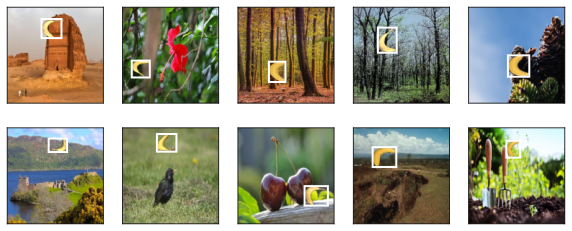

In [84]:
imgs = (batch[0][:10].permute(0, 2, 3, 1)) / 255
axes = d2l.show_images(imgs, 2, 5, scale=2)
for ax, label in zip(axes, batch[1][:10]):
    d2l.show_bboxes(ax, [label[0][1:5] * edge_size], colors=['w'])

### 14.6.4 Summary
* Introduce custom d2l banana object detection dataset
* Usually need the same number of bounding boxes per minibatch for dimensinality matches, but can get around this by just padding with illegal bounding boxes

### 14.6.5 Exercises
1. Demonstrate other images with ground-truth bounding boxes in the banana detection dataset. How do they differ with respect to bounding boxes and objects?
1. Say that we want to apply data augmentation, such as random cropping, to object detection. How can it be different from that in image classification? Hint: what if a cropped image only contains a small portion of an object?

# 14.7 Single Shot Multibox Detection (long asf)

### 14.7.1 Model

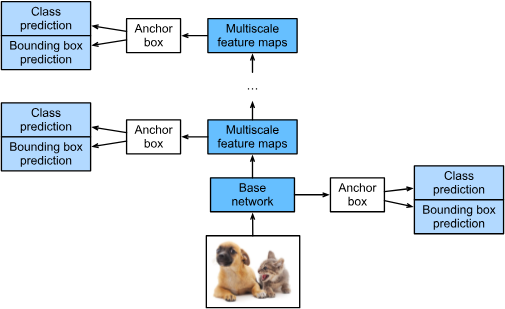

* Figure above is overview of design of single-shot multibox detection 
* Model mainly consists of base network followed by several multiscale feature map blocks
* Base network is for extracting features from input image, so it can se a deep CNN
    * Note - original single-shot multibox detection paper adopts a VGG network truncated before the classification layer, while ResNet has also been commonly used
* Essentially, the base network and several multiscale feature map blocks, single-shot multibox detectino generates a varying number of anchor boxes with different sizes, and detects objects of varying sizes by predicting classes and offsets of these anchor boxes (and thus the bounding boxes)

### 14.7.1.1 Class Prediction Layer
* Let the number of object classes be $q$
    * Then, the anchor boxes would have $q+1$ classes, where the additional 1 is for class 0, the background class
* At some scale, suppose that the height and width of feature maps are $h$ and $w$ respectively
* When $a$ anchor boxes are generated with each spatial position of these feature amps as their center, a total of $hwa$ anchor boxes need to be classified
* This often makes classificatino with FC layers infeasbile due to heavy parametrization costs
* Recall: How we used channels of convolutional layers to predict classes (Section 8.3). Single-Shot Multibox Detection uses the same technique to reduce model complexity
* Specifically, class prediction layer uses a Conv Layer without altering the height or width of feature maps
    * In this way, there can be one-to-one correspondence between outputs and inputs at same spatial dimensions (height and width) of feature maps
    * More concretely - channels of the output feature amps at any spatial position $(x, y)$ represent class predictions for all the anchor boxes centered on $(x, y)$ of the input feature maps
    * To produce valid predictins, there must be $a(q+1)$ output channels, where for the same spatial position the output channel with index $i(q+1)+j$ represents the prediction of the class $j$ where $0 \leq j \leq q$ for the anchor box $i$ (where $(0 \leq i < a)$)
* We define a class prediction layer by specifying arguments $a$ and $q$ via _num_anchors_ and _num_classes_. This layer will use a $3\times 3$ convolutional layer with padding of 1. (Thus, the height and width of input and output of convolutional layer are the same)

In [85]:
%matplotlib inline
import torch
import torchvision
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l


def cls_predictor(num_inputs, num_anchors, num_classes):
    return nn.Conv2d(num_inputs, num_anchors * (num_classes + 1),
                     kernel_size=3, padding=1)

### 14.7.1.2 Bounding Box Prediction Layer

* Design of bounding box prediction layer is similar to that of class prediction layer - only difference is number of outputs for each anchor box - we need to predict 4 offsets rather than $q+1$ classes

In [86]:
def bbox_predictor(num_inputs, num_anchors):
    return nn.Conv2d(num_inputs, num_anchors * 4, kernel_size=3, padding=1)

### 14.7.1.3 Concatenating Predictions for Multiple Scales
* Single-shot multibox detection uses multiscale feature maps to generate anchor boxes and predict their classes and offsets
* At different scales, the shapes of feature maps or the number of anchor boxes centered on the same unit may vary
* Therefore, shapes of the prediction outouts at different scales may vary
* In the following examples:
    

### 14.7.1.4 Downsampling Block

### 14.7.1.5 Base Network Block

### 14.7.1.6 The Complete Model

### 14.7.2 Training

### 14.7.3 Prediction

### 14.7.4 Summary

### 14.7.5 Exercises
1. Can you improve the single-shot multibox detection by improving the loss function? For example, replace $\ell_1$ norm loss with smooth $\ell_1$ norm loss for the predicted offsets. This loss function uses a square function around zero for smoothness, which is controlled by the hyperparameter $\sigma$:

2. Due to space limitations, we have omitted some implementation details of the single shot multibox detection model in this section. Can you further improve the model in the following aspects:
    1. When an object is much smaller compared with the image, the model could resize the input image bigger.
    1. There are typically a vast number of negative anchor boxes. To make the class distribution more balanced, we could downsample negative anchor boxes.
    1. In the loss function, assign different weight hyperparameters to the class loss and the offset loss.
    1. Use other methods to evaluate the object detection model, such as those in the single shot multibox detection paper :cite:`Liu.Anguelov.Erhan.ea.2016`.



# 14.8 Region-based CNNs (R-CNNs) (p short)

### 14.8.1 R-CNNs

### 14.8.2 Fast R-CNN

### 14.8.3 Faster R-CNN

### 14.8.4 Mask R-CNN

### 14.8.5 Summary

### 14.8.6 Exercises
1. Can we frame object detection as a single regression problem, such as predicting bounding boxes and class probabilities? You may refer to the design of the YOLO model Redmon.Divvala.Girshick.ea.2016.
1. Compare single shot multibox detection with the methods introduced in this section. What are their major differences? You may refer to Figure 2 of Zhao.Zheng.Xu.ea.2019.


# 14.9 Semantic Segmentation and the Dataset (errs on longer side)

### 14.9.1 Image Segmentation and Instance Segmentation

### 14.9.2 The Pascal VOC2012 Semantic Segmentation Dataset

### 14.9.3 Summary

### 14.9.4 Exercises
1. How can semantic segmentation be applied in autonomous vehicles and medical image diagnostics? Can you think of other applications?
1. Recall the descriptions of data augmentation in :numref:`sec_image_augmentation`. Which of the image augmentation methods used in image classification would be infeasible to be applied in semantic segmentation?

# 14.10 Transposed Convolution (kinda short)

### 14.10.1 Basic Operation

### 14.10.2 Padding, Strides, and Multiple Channels

### 14.10.3 Connection to Matrix Transposition

### 14.10.4 Summary

### 14.10.5 Exercises
1. In :numref:`subsec-connection-to-mat-transposition`, the convolution input `X` and the transposed convolution output `Z` have the same shape. Do they have the same value? Why?
1. Is it efficient to use matrix multiplications to implement convolutions? Why?

# 14.11 Fully Convolutional Networks (medium)

### 14.11.1 The Model

### 14.11.2 Initializing Transposed Convolutional Layers

### 14.11.3 Reading the Dataset

### 14.11.4 Training

### 14.11.5 Prediction

### 14.11.6 Summary

### 14.11.7 Exercises
1. If we use Xavier initialization for the transposed convolutional layer in the experiment, how does the result change?
1. Can you further improve the accuracy of the model by tuning the hyperparameters?
1. Predict the classes of all pixels in test images.
1. The original fully convolutional network paper also uses outputs of some intermediate CNN layers Long.Shelhamer.Darrell.2015. Try to implement this idea.

# 14.12 Neural Style Transfer (errs on longer side)

### 14.12.1 Method

### 14.12.2 Reading the Content and Style Images

### 14.12.3 Preprocessing and Postprocessing

### 14.12.4 Extracting Features

### 14.12.5 Defining the Loss Function

### 14.12.6 Initializing the Synthesized Image

### 14.12.7 Training

### 14.12.8 Summary

### 14.12.9 Exercises
1. How does the output change when you select different content and style layers?
1. Adjust the weight hyperparameters in the loss function. Does the output retain more content or have less noise?
1. Use different content and style images. Can you create more interesting synthesized images?
1. Can we apply style transfer for text? Hint: you may refer to the survey paper by 10.1145/3544903.3544906.


# 14.13 Image Classification (CIFAR-10) on Kaggle (medium)

### 14.13.1 Obtaining and Organizing the Dataset

### 14.13.2 Image Augmentation

### 14.13.3 Reading the Dataset

### 14.13.4 Defining the Model

### 14.13.5 Defining the Training Function

### 14.13.6 Training and Validating the Model

### 14.13.7 Classifying the Testing Set and Submitting Results on Kaggle

### 14.13.8 Summary

### 14.13.9 Exercises
1. Use the complete CIFAR-10 dataset for this Kaggle competition. Set hyperparameters as `batch_size = 128`, `num_epochs = 100`, `lr = 0.1`, `lr_period = 50`, and `lr_decay = 0.1`.  See what accuracy and ranking you can achieve in this competition. Can you further improve them?
1. What accuracy can you get when not using image augmentation?

# 14.14 Dog Breed Identification (ImageNet Dogs) on Kaggle (medium)

### 14.14.1 Obtaining and Organizing the Dataset

### 14.14.2 Image Augmentation

### 14.14.3 Reading the Dataset

### 14.14.4 Fine-Tuning a Pretrained Model

### 14.14.5 Defining the Training Function

### 14.14.6 Training and Validating the Model

### 14.14.7 Classifying the Testing Set and Submitting Results on Kaggle

### 14.14.8 Summary

### 14.14.9 Exercises
1. When using the full Kaggle competition dataset, what results can you achieve when you increase `batch_size` (batch size) and `num_epochs` (number of epochs) while setting some other hyperparameters as `lr = 0.01`, `lr_period = 10`, and `lr_decay = 0.1`?
1. Do you get better results if you use a deeper pretrained model? How do you tune hyperparameters? Can you further improve the results?